 **Trabajo ISING MODEL**

Dependencias

In [ ]:
!pip install qiskit
!pip install qiskit-ibm-runtime
!pip install qiskit[visualization]
!pip install qiskit-aer

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.3/6.3 MB 14.0 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.2/2.2 MB 31.7 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 49.6/49.6 kB 2.4 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 116.3/116.3 kB 8.1 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 49.6/49.6 kB 3.5 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 39.4/39.4 MB 14.5 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 107.5/107.5 kB 5.3 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.8/1.8 MB 5.6 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 301.9/301.9 kB 23.0 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 245.9/245.9 kB 20.4 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 59.1/59.1 kB

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from qiskit import QuantumCircuit, Aer, transpile, assemble, QuantumRegister, ClassicalRegister, BasicAer
from qiskit.visualization import plot_histogram
from numpy import pi

from qiskit.visualization import plot_state_city, plot_bloch_multivector
from qiskit.visualization import plot_state_paulivec, plot_state_hinton
from qiskit.visualization import plot_state_qsphere

Circuito en cuestión a mandar a IBM, depende del valor de lambda que metas, este es el circuito para el estado inicial

In [ ]:
qreg_q = QuantumRegister(4, 'q')
creg_c = ClassicalRegister(4, 'c')
circuit = QuantumCircuit(qreg_q, creg_c)
initial_state = [1, 0, 0, 0,0,0,0,0,0,0,0,0,0,0,0,0]  # Amplitude for |0000⟩ is 1, all others are 0
 # Initialize the quantum circuit to the desired state
circuit.initialize(initial_state, circuit.qubits)

    #variables
k=1
n=4
lamb=0.5
theta0 =np.arccos((lamb-np.cos(2*pi*0/n))/(np.sqrt((lamb-np.cos(2*pi*0/n))**2+np.sin(2*pi*0/n)**2)))
theta1 =np.arccos((lamb-np.cos(2*pi*1/n))/(np.sqrt((lamb-np.cos(2*pi*k/n))**2+np.sin(2*pi*k/n)**2)))

#circuit.x(qreg_q[1])   #meter esta línea si quieres iniciar en el estado |0001> en vez de en el |0000>

circuit.x(qreg_q[1])
circuit.x(qreg_q[3])
circuit.cx(qreg_q[1], qreg_q[0])
circuit.cx(qreg_q[3], qreg_q[2])
circuit.rz(pi / 2, qreg_q[1])
circuit.rz(pi / 2, qreg_q[3])
circuit.cx(qreg_q[0], qreg_q[1])
circuit.cx(qreg_q[2], qreg_q[3])
circuit.ry(-theta1 / 2, qreg_q[1])
# here we have +pi/2 as it is the transpose conjugate
circuit.ry(-theta0 / 2, qreg_q[3])
circuit.cx(qreg_q[0], qreg_q[1])
circuit.cx(qreg_q[2], qreg_q[3])
circuit.ry(theta1 / 2, qreg_q[1])
circuit.ry(theta0 / 2, qreg_q[3])
circuit.rz(-pi / 2, qreg_q[1])
circuit.rz(-pi / 2, qreg_q[3])
circuit.cx(qreg_q[1], qreg_q[0])
circuit.cx(qreg_q[3], qreg_q[2])
circuit.x(qreg_q[1])
circuit.x(qreg_q[3])
circuit.cz(qreg_q[0], qreg_q[1])
circuit.cz(qreg_q[2], qreg_q[3])
circuit.cx(qreg_q[0], qreg_q[1])
circuit.cx(qreg_q[2], qreg_q[3])
    #ch's to be changed
circuit.h(qreg_q[0])
circuit.cx(qreg_q[1], qreg_q[0])
circuit.h(qreg_q[0])

circuit.h(qreg_q[2])
circuit.cx(qreg_q[3], qreg_q[2])
circuit.h(qreg_q[2])

circuit.cx(qreg_q[0], qreg_q[1])
circuit.cx(qreg_q[2], qreg_q[3])
circuit.u(0, 0, -2 * pi / 4, qreg_q[0])
circuit.u(0, 0, 0, qreg_q[2])
circuit.cx(qreg_q[1], qreg_q[2])
circuit.cx(qreg_q[2], qreg_q[1])
circuit.cx(qreg_q[1], qreg_q[2])
circuit.h(qreg_q[2])
circuit.cx(qreg_q[1], qreg_q[2])
circuit.h(qreg_q[2])
circuit.cz(qreg_q[0], qreg_q[1])
circuit.cx(qreg_q[0], qreg_q[1])
circuit.cz(qreg_q[2], qreg_q[3])

circuit.h(qreg_q[0])
circuit.cx(qreg_q[1], qreg_q[0])
circuit.h(qreg_q[0])
circuit.cx(qreg_q[2], qreg_q[3])
circuit.cx(qreg_q[0], qreg_q[1])
circuit.h(qreg_q[2])
circuit.cx(qreg_q[3], qreg_q[2])
circuit.h(qreg_q[2])

circuit.u(0, 0, 0, qreg_q[0])
circuit.cx(qreg_q[2], qreg_q[3])
circuit.u(0, 0, 0, qreg_q[2])
circuit.cx(qreg_q[1], qreg_q[2])
circuit.cx(qreg_q[2], qreg_q[1])
circuit.cx(qreg_q[1], qreg_q[2])
circuit.h(qreg_q[2])
circuit.cx(qreg_q[1], qreg_q[2])
circuit.h(qreg_q[2])

circuit.measure_all()

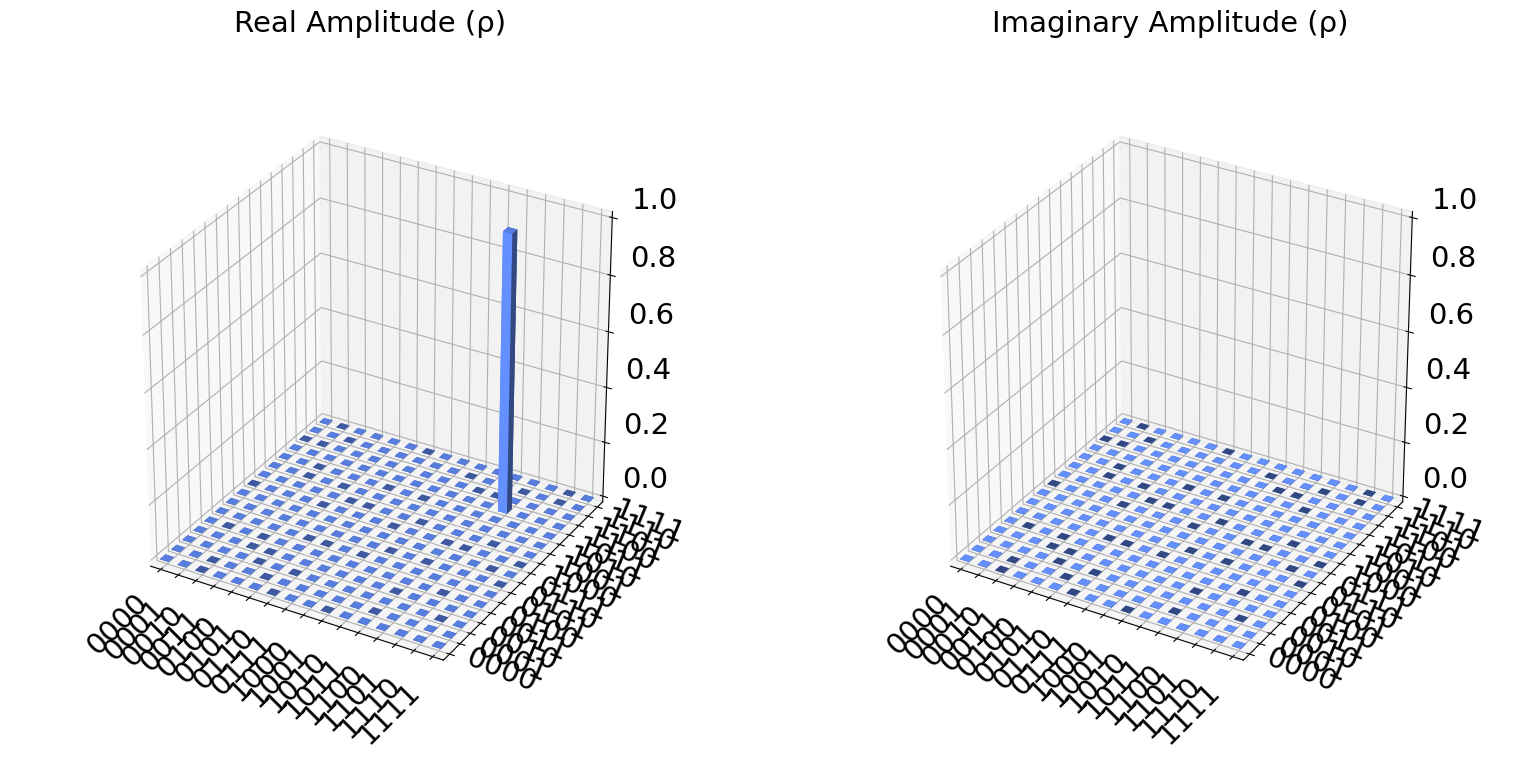

In [ ]:
# Some facts about the final state

backend = BasicAer.get_backend('statevector_simulator') # the device to run on
result = backend.run(transpile(circuit, backend)).result()
psi  = result.get_statevector(circuit)
plot_state_city(psi)

In [ ]:
from qiskit.opflow import X, Y, Z, I
from qiskit.quantum_info import Operator

# Define the total sigma_z operator for 4 qubits
sigma_z_4q = Operator.from_label('Z' * 4)
#sigma_z_4q = Operator.from_label('Z')


# Evolve the state to the final state (replace with your actual circuit)
final_state = Aer.get_backend('statevector_simulator').run(circuit).result().get_statevector()

# Calculate the expectation value
#expectation_value = sigma_z_4q.expectation_value(final_state)
#expectation_value = np.real(np.vdot(final_state, sigma_z_4q.data @ final_state))
#expectation_value = np.real(final_state.adjoint().data @ sigma_z_4q.data @ final_state.data)
expectation_value = np.real(np.conjugate(final_state.data) @ sigma_z_4q.data @ final_state.data)

# Print or use the expectation value as needed
print(f"Expectation Value of Sigma_z for 4 Qubits: {expectation_value}")

<ipython-input-13-a93f5e1ecca6>:1: DeprecationWarning: The ``qiskit.opflow`` module is deprecated as of qiskit-terra 0.24.0. It will be removed no earlier than 3 months after the release date. For code migration guidelines, visit https://qisk.it/opflow_migration.
  from qiskit.opflow import X, Y, Z, I


NameError: ignored

*Figura 5 del paper*.

```
# This is formatted as code
```



Aquí he hecho esto para jugar con los parámetros(lambda) a mano y mandarlo a IBM

In [ ]:
lamb=0
k=1
n=4
theta0 =np.arccos((lamb-np.cos(2*pi*0/n))/(np.sqrt((lamb-np.cos(2*pi*0/n))**2+np.sin(2*pi*0/n)**2)))
theta1 =np.arccos((lamb-np.cos(2*pi*1/n))/(np.sqrt((lamb-np.cos(2*pi*k/n))**2+np.sin(2*pi*k/n)**2)))
print('theta0=',theta0)
print('theta1=',theta1)

lambda_values = np.linspace(0, 1.75,10)
theta0v= np.zeros(10)
theta1v=np.zeros(10)

theta0v =np.arccos((lambda_values-np.cos(2*pi*0/n))/(np.sqrt((lambda_values-np.cos(2*pi*0/n))**2+np.sin(2*pi*0/n)**2)))
theta1v =np.arccos((lambda_values-np.cos(2*pi*1/n))/(np.sqrt((lambda_values-np.cos(2*pi*k/n))**2+np.sin(2*pi*k/n)**2)))

print('lambda_values=',lambda_values)
print('theta0v=',theta0v)
print('theta1v=',theta1v)



theta0= 3.141592653589793
theta1= 1.5707963267948968
lambda_values= [0.         0.19444444 0.38888889 0.58333333 0.77777778 0.97222222
 1.16666667 1.36111111 1.55555556 1.75      ]
theta0v= [3.14159265 3.14159265 3.14159265 3.14159265 3.14159265 3.14159265
 0.         0.         0.         0.        ]
theta1v= [1.57079633 1.37874831 1.19990504 1.04272188 0.90975316 0.79948174
 0.70862627 0.63363301 0.57133748 0.51914611]


aqui esta la movie

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from qiskit import QuantumCircuit, Aer, transpile, assemble, QuantumRegister, ClassicalRegister
from qiskit.visualization import plot_histogram
from numpy import pi

# Function to create the quantum circuit
def create_circuit(lamb,my_bool_argument=False):
    qreg_q = QuantumRegister(4, 'q')
    circuit = QuantumCircuit(qreg_q)
    initial_state = [1, 0, 0, 0,0,0,0,0,0,0,0,0,0,0,0,0]  # Amplitude for |0000⟩ is 1, all others are 0
    # # Initialize the quantum circuit to the desired state
    circuit.initialize(initial_state, circuit.qubits)

    #variables
    k=1
    n=4
    #lamb= 0.5
    theta0 =np.arccos((lamb-np.cos(2*pi*0/n))/(np.sqrt((lamb-np.cos(2*pi*0/n))**2+np.sin(2*pi*0/n)**2)))
    theta1 =np.arccos((lamb-np.cos(2*pi*1/n))/(np.sqrt((lamb-np.cos(2*pi*k/n))**2+np.sin(2*pi*k/n)**2)))
    circuit.x(qreg_q[1])
    circuit.x(qreg_q[3])
    circuit.cx(qreg_q[1], qreg_q[0])
    circuit.cx(qreg_q[3], qreg_q[2])
    circuit.rz(pi / 2, qreg_q[1])
    circuit.rz(pi / 2, qreg_q[3])
    circuit.cx(qreg_q[0], qreg_q[1])
    circuit.cx(qreg_q[2], qreg_q[3])
    circuit.ry(-theta1 / 2, qreg_q[1])
# here we have +pi/2 as it is the transpose conjugate
    circuit.ry(-theta0 / 2, qreg_q[3])
    circuit.cx(qreg_q[0], qreg_q[1])
    circuit.cx(qreg_q[2], qreg_q[3])
    circuit.ry(theta1 / 2, qreg_q[1])
    circuit.ry(theta0 / 2, qreg_q[3])
    circuit.rz(-pi / 2, qreg_q[1])
    circuit.rz(-pi / 2, qreg_q[3])
    circuit.cx(qreg_q[1], qreg_q[0])
    circuit.cx(qreg_q[3], qreg_q[2])
    circuit.x(qreg_q[1])
    circuit.x(qreg_q[3])
    circuit.cz(qreg_q[0], qreg_q[1])
    circuit.cz(qreg_q[2], qreg_q[3])
    circuit.cx(qreg_q[0], qreg_q[1])
    circuit.cx(qreg_q[2], qreg_q[3])
    #ch's to be changed
    circuit.h(qreg_q[0])
    circuit.cx(qreg_q[1], qreg_q[0])
    circuit.h(qreg_q[0])

    circuit.h(qreg_q[2])
    circuit.cx(qreg_q[3], qreg_q[2])
    circuit.h(qreg_q[2])

    circuit.cx(qreg_q[0], qreg_q[1])
    circuit.cx(qreg_q[2], qreg_q[3])
    circuit.u(0, 0, -2 * pi / 4, qreg_q[0])
    circuit.u(0, 0, 0, qreg_q[2])
    circuit.cx(qreg_q[1], qreg_q[2])
    circuit.cx(qreg_q[2], qreg_q[1])
    circuit.cx(qreg_q[1], qreg_q[2])
    circuit.h(qreg_q[2])
    circuit.cx(qreg_q[1], qreg_q[2])
    circuit.h(qreg_q[2])
    circuit.cz(qreg_q[0], qreg_q[1])
    circuit.cx(qreg_q[0], qreg_q[1])
    circuit.cz(qreg_q[2], qreg_q[3])

    circuit.h(qreg_q[0])
    circuit.cx(qreg_q[1], qreg_q[0])
    circuit.h(qreg_q[0])
    circuit.cx(qreg_q[2], qreg_q[3])
    circuit.cx(qreg_q[0], qreg_q[1])
    circuit.h(qreg_q[2])
    circuit.cx(qreg_q[3], qreg_q[2])
    circuit.h(qreg_q[2])

    circuit.u(0, 0, 0, qreg_q[0])
    circuit.cx(qreg_q[2], qreg_q[3])
    circuit.u(0, 0, 0, qreg_q[2])
    circuit.cx(qreg_q[1], qreg_q[2])
    circuit.cx(qreg_q[2], qreg_q[1])
    circuit.cx(qreg_q[1], qreg_q[2])
    circuit.h(qreg_q[2])
    circuit.cx(qreg_q[1], qreg_q[2])
    circuit.h(qreg_q[2])

    # Apply gates based on the lambda parameter
    # Modify this part based on your specific circuit

    # Measure all qubits
    if my_bool_argument:
      circuit.measure_all()

    return circuit

In [ ]:
#circuito con el estado inicial |0001>

import numpy as np
import matplotlib.pyplot as plt
from qiskit import QuantumCircuit, Aer, transpile, assemble, QuantumRegister, ClassicalRegister
from qiskit.visualization import plot_histogram
from numpy import pi

# Function to create the quantum circuit
def create_circuit2(lamb,my_bool_argument=False):
    qreg_q = QuantumRegister(4, 'q')
    circuit = QuantumCircuit(qreg_q)
    initial_state = [1, 0, 0, 0,0,0,0,0,0,0,0,0,0,0,0,0]  # Amplitude for |0000⟩ is 1, all others are 0
    # # Initialize the quantum circuit to the desired state
    circuit.initialize(initial_state, circuit.qubits)

    #variables
    k=1
    n=4
    #lamb= 0.5
    theta0 =np.arccos((lamb-np.cos(2*pi*0/n))/(np.sqrt((lamb-np.cos(2*pi*0/n))**2+np.sin(2*pi*0/n)**2)))
    theta1 =np.arccos((lamb-np.cos(2*pi*1/n))/(np.sqrt((lamb-np.cos(2*pi*k/n))**2+np.sin(2*pi*k/n)**2)))
    circuit.x(qreg_q[3])
    circuit.x(qreg_q[1])
    circuit.x(qreg_q[3])
    circuit.cx(qreg_q[1], qreg_q[0])
    circuit.cx(qreg_q[3], qreg_q[2])
    circuit.rz(pi / 2, qreg_q[1])
    circuit.rz(pi / 2, qreg_q[3])
    circuit.cx(qreg_q[0], qreg_q[1])
    circuit.cx(qreg_q[2], qreg_q[3])
    circuit.ry(-theta1 / 2, qreg_q[1])
# here we have +pi/2 as it is the transpose conjugate
    circuit.ry(-theta0 / 2, qreg_q[3])
    circuit.cx(qreg_q[0], qreg_q[1])
    circuit.cx(qreg_q[2], qreg_q[3])
    circuit.ry(theta1 / 2, qreg_q[1])
    circuit.ry(theta0 / 2, qreg_q[3])
    circuit.rz(-pi / 2, qreg_q[1])
    circuit.rz(-pi / 2, qreg_q[3])
    circuit.cx(qreg_q[1], qreg_q[0])
    circuit.cx(qreg_q[3], qreg_q[2])
    circuit.x(qreg_q[1])
    circuit.x(qreg_q[3])
    circuit.cz(qreg_q[0], qreg_q[1])
    circuit.cz(qreg_q[2], qreg_q[3])
    circuit.cx(qreg_q[0], qreg_q[1])
    circuit.cx(qreg_q[2], qreg_q[3])
    #ch's to be changed
    circuit.h(qreg_q[0])
    circuit.cx(qreg_q[1], qreg_q[0])
    circuit.h(qreg_q[0])

    circuit.h(qreg_q[2])
    circuit.cx(qreg_q[3], qreg_q[2])
    circuit.h(qreg_q[2])

    circuit.cx(qreg_q[0], qreg_q[1])
    circuit.cx(qreg_q[2], qreg_q[3])
    circuit.u(0, 0, -2 * pi / 4, qreg_q[0])
    circuit.u(0, 0, 0, qreg_q[2])
    circuit.cx(qreg_q[1], qreg_q[2])
    circuit.cx(qreg_q[2], qreg_q[1])
    circuit.cx(qreg_q[1], qreg_q[2])
    circuit.h(qreg_q[2])
    circuit.cx(qreg_q[1], qreg_q[2])
    circuit.h(qreg_q[2])
    circuit.cz(qreg_q[0], qreg_q[1])
    circuit.cx(qreg_q[0], qreg_q[1])
    circuit.cz(qreg_q[2], qreg_q[3])

    circuit.h(qreg_q[0])
    circuit.cx(qreg_q[1], qreg_q[0])
    circuit.h(qreg_q[0])
    circuit.cx(qreg_q[2], qreg_q[3])
    circuit.cx(qreg_q[0], qreg_q[1])
    circuit.h(qreg_q[2])
    circuit.cx(qreg_q[3], qreg_q[2])
    circuit.h(qreg_q[2])

    circuit.u(0, 0, 0, qreg_q[0])
    circuit.cx(qreg_q[2], qreg_q[3])
    circuit.u(0, 0, 0, qreg_q[2])
    circuit.cx(qreg_q[1], qreg_q[2])
    circuit.cx(qreg_q[2], qreg_q[1])
    circuit.cx(qreg_q[1], qreg_q[2])
    circuit.h(qreg_q[2])
    circuit.cx(qreg_q[1], qreg_q[2])
    circuit.h(qreg_q[2])

    # Measure all qubits
    if my_bool_argument:
      circuit.measure_all()

    return circuit


In [ ]:
# from qiskit.quantum_info import PauliExpectation, AerPauliExpectation, PauliSumOp

# lambda_values= [0.         0.19444444 0.38888889 0.58333333 0.77777778 0.97222222 1.16666667 1.36111111 1.55555556 1.75      ]
# theta0v= [3.14159265 3.14159265 3.14159265 3.14159265 3.14159265 3.14159265  0.         0.         0.         0.        ]
#theta1v= [1.57079633 1.37874831 1.19990504 1.04272188 0.90975316 0.79948174 0.70862627 0.63363301 0.57133748 0.51914611]


# lambda 0
mean_sigz_med_qyoto= np.zeros(10)
# Example: Use a quasi_dist array representing the measurement outcomes
quasi_dist = [
	{
		"1000": -0.06388419628302254,
		"1001": 0.43461658066521375,
		"1100": 0.31432147721145154,
		"1101": 0.1081095216098957,
		"0000": 0.0545362570792444,
		"0001": -0.02977078914547082,
		"0100": -0.11996464610388927,
		"0101": 0.30203579496657723
	}
]

mean_sigz=((0.08600749685464502)**1+(0.08745892644860463)**1+( 0.06929423637219724)**1)*2+((0.1776936919649616)**1)*(-2)+(0.11683701152386561**1)*4
mean_sigz_med= 0.25*mean_sigz
mean_sigz_med_qyoto[0]=mean_sigz_med
print("Observable Mean:", mean_sigz_med)

# lambda  0.19444444
# Example: Use a quasi_dist array representing the measurement outcomes
quasi_dist = [
	{
		"1000": 0.1243963777487016,
		"1001": 0.18141718019002442,
		"1100": 0.09282355525923053,
		"1101": 0.08485664336667707,
		"0000": 0.16165631108950554,
		"0001": 0.14037861584530664,
		"0100": 0.08441014217476332,
		"0101": 0.1300611743257909
	}
]
mean_sigz=((0.1243963777487016)**1+(0.14037861584530664)**1+(0.08441014217476332)**1)*2+((0.08485664336667707)**1)*(-2)+( 0.16165631108950554**1)*4
mean_sigz_med= 0.25*mean_sigz
mean_sigz_med_qyoto[1]=mean_sigz_med
print("Observable Mean:", mean_sigz_med)



# lambda  0.38888889
# Example: Use a quasi_dist array representing the measurement outcomes
quasi_dist = [
	{
		"1000": 0.17839641795832575,
		"1001": 0.062391423095104794,
		"1100": 0.040968593295103134,
		"1101": 0.1506798271840376,
		"0000": 0.1561827220024591,
		"0001": 0.19671047427345079,
		"0100": 0.1336863113382458,
		"0101": 0.08098423085327304
	}
]
mean_sigz=((0.17839641795832575)**1+(0.19671047427345079)**1+(0.1336863113382458)**1)*2+((0.1506798271840376)**1)*(-2)+(0.1561827220024591**1)*4
mean_sigz_med= 0.25*mean_sigz
mean_sigz_med_qyoto[2]=mean_sigz_med
print("Observable Mean:", mean_sigz_med)

# lambda  0.58333333
# Example: Use a quasi_dist array representing the measurement outcomes
quasi_dist = [
	{
		"1000": 0.22872406901578302,
		"1001": 0.06841410473944964,
		"1100": 0.016114666112887355,
		"1101": 0.11214955923775091,
		"0000": 0.13820543383985115,
		"0001": 0.19697549193207486,
		"0100": 0.1548043731950642,
		"0101": 0.08461230192713876
	}
]
mean_sigz=((0.22872406901578302)**1+(0.19697549193207486)**1+(0.1548043731950642)**1)*2+((0.11214955923775091)**1)*(-2)+( 0.13820543383985115)*4
mean_sigz_med= 0.25*mean_sigz
mean_sigz_med_qyoto[3]=mean_sigz_med
print("Observable Mean:", mean_sigz_med)


# lambda  0.7777
quasi_dist=[
	{
		"1000": 0.21488588254476676,
		"1001": 0.07795866059962746,
		"1100": 0.0239980119364997,
		"1101": 0.11044711290255241,
		"0000": 0.1163415518267341,
		"0001": 0.21922152894699418,
		"0100": 0.1887159466154391,
		"0101": 0.0484313046273863
	}
]
mean_sigz=((0.21488588254476676)**1+(0.21922152894699418)**1+(0.1887159466154391)**1)*2+((0.11044711290255241)**1)*(-2)+(0.1163415518267341)*4
mean_sigz_med= 0.25*mean_sigz
mean_sigz_med_qyoto[4]=mean_sigz_med
print("Observable Mean:", mean_sigz_med)


# lambda 0.97

quasi_dist = [
    {
      "1000": 0.2692065135580904,
      "1001": 0.007329846270998076,
      "1100": -0.008695490444627326,
      "1101": 0.11687609808857552,
      "0000": 0.18947825451732284,
      "0001": 0.19059475405589002,
      "0100": 0.21009067692249553,
      "0101": 0.025119347031254922
    }
  ]

mean_sigz=((0.2692065135580904)**1+(0.19059475405589002)**1+(0.21009067692249553)**1)*2+((0.11687609808857552)**1)*(-2)+(0.18947825451732284)*4
mean_sigz_med= 0.25*mean_sigz
mean_sigz_med_qyoto[5]=mean_sigz_med
print("Observable Mean:", mean_sigz_med)

# lambda 1.16


quasi_dist =[
    {
      "1000": -0.18105126053819054,
      "1001": 0.15908294050481633,
      "1100": 0.0352645537575193,
      "1101": -0.0038643668673143277,
      "0000": 1.1581525278425353,
      "0001": -0.26322192794243093,
      "0100": 0.0239523457624738,
      "0101": 0.07168518748059104
    }
  ]

mean_sigz=((-0.18105126053819054)**1+(0.0239523457624738)**1+(-0.26322192794243093)**1)*2+(( -0.0038643668673143277)**1)*(-2)+(1.1581525278425353)*4
mean_sigz_med= 0.25*mean_sigz
mean_sigz_med_qyoto[6]=mean_sigz_med
print("Observable Mean:", mean_sigz_med)

# lamb 1,36

quasi_dist= [
	{
		"1000": -0.1730771797996516,
		"1001": 0.187970915359954,
		"1100": 0.024440278648811747,
		"1101": 0.014062253963021474,
		"0000": 1.142956911080145,
		"0001": -0.26199036068355813,
		"0100": 0.03080961245379012,
		"0101": 0.034827568977487455
	}
]

mean_sigz=((-0.1730771797996516)**1+(-0.26199036068355813)**1+(0.03080961245379012)**1)*2+((0.024440278648811747)**1)*(-2)+(1.142956911080145)*4
mean_sigz_med= 0.25*mean_sigz
mean_sigz_med_qyoto[7]=mean_sigz_med
print("Observable Mean:", mean_sigz_med)

# lamb 1,5

quasi_dist= [
	{
		"1000": -0.2861293548264814,
		"1001": 0.2556491743837446,
		"1100": 0.0919572666918445,
		"1101": -0.03328087726902404,
		"0000": 1.4737547001981826,
		"0001": -0.5365613851456884,
		"0100": -0.040512096629433524,
		"0101": 0.07512257259685567
	}
]

mean_sigz=((-0.2861293548264814)**1+(-0.5365613851456884)**1+(-0.040512096629433524)**1)*2+((0.0919572666918445)**1)*(-2)+(1.4737547001981826)*4
mean_sigz_med= 0.25*mean_sigz
mean_sigz_med_qyoto[8]=mean_sigz_med
print("Observable Mean:", mean_sigz_med)

# lamb 1,75

quasi_dist= [
	{
		"1000": -0.22938520347345154,
		"1001": 0.2011262827315216,
		"1100": 0.06230186926727369,
		"1101": -0.01947112455480758,
		"0000": 1.3791898474681386,
		"0001": -0.48245369574592595,
		"0100": 0.07067397590074752,
		"0101": 0.01801804840650358
	}
]

mean_sigz=((-0.22938520347345154)**1+(-0.48245369574592595)**1+(0.07067397590074752)**1)*2+((-0.01947112455480758)**1)*(-2)+(1.3791898474681386)*4
mean_sigz_med= 0.25*mean_sigz
mean_sigz_med_qyoto[9]=mean_sigz_med
print("Observable Mean:", mean_sigz_med)




mean_sigz_med_qyoto


Observable Mean: 0.14937049537910826
Observable Mean: 0.2938205572905528
Observable Mean: 0.33523941019545145
Observable Mean: 0.3723826212924367
Observable Mean: 0.37252967442905793
Observable Mean: 0.46598617774127304
Observable Mean: 0.9499242899171186
Observable Mean: 0.9286078077410292
Observable Mean: 0.9961746485514587
Observable Mean: 1.0683429480862274


array([0.1493705 , 0.29382056, 0.33523941, 0.37238262, 0.37252967,
       0.46598618, 0.94992429, 0.92860781, 0.99617465, 1.06834295])

In [ ]:
# 2048 shots

# lambda 0
mean_sigz_med_qyoto_2048= np.zeros(10)
# Example: Use a quasi_dist array representing the measurement outcomes
quasi_dist = [
	{
		"1000": 0.08600749685464502,
		"1001": 0.21984293298343713,
		"1100": 0.10781870882917079,
		"1101": 0.1776936919649616,
		"0000": 0.11683701152386561,
		"0001": 0.08745892644860463,
		"0100": 0.06929423637219724,
		"0101": 0.13504699502311798
	}
]

mean_sigz=((0.08600749685464502)**1+(0.08745892644860463)**1+( 0.06929423637219724)**1)*2+((0.1776936919649616)**1)*(-2)+(0.11683701152386561**1)*4
mean_sigz_med= 0.25*mean_sigz
mean_sigz_med_qyoto_2048[0]=mean_sigz_med
print("Observable Mean:", mean_sigz_med)

# lambda  0.19444444
# Example: Use a quasi_dist array representing the measurement outcomes
quasi_dist = [
	{
		"1000": 0.1105212126966714,
		"1001": 0.14724831983418507,
		"1100": 0.12557760607534849,
		"1101": 0.14666628894659886,
		"0000": 0.1415094490571423,
		"0001": 0.14239276890171396,
		"0100": 0.07815637402106973,
		"0101": 0.10792798046727022
	}
]
mean_sigz=((0.1105212126966714)**1+(0.14239276890171396)**1+(0.07815637402106973)**1)*2+((0.14666628894659886)**1)*(-2)+( 0.1415094490571423**1)*4
mean_sigz_med= 0.25*mean_sigz
mean_sigz_med_qyoto_2048[1]=mean_sigz_med
print("Observable Mean:", mean_sigz_med)



# lambda  0.38888889
# Example: Use a quasi_dist array representing the measurement outcomes
quasi_dist = [
	{
		"1000": 0.13143581124417042,
		"1001": 0.17696516252761968,
		"1100": 0.09978909041481268,
		"1101": 0.13000875650920873,
		"0000": 0.14180074808827603,
		"0001": 0.12487747752590356,
		"0100": 0.12700355548374012,
		"0101": 0.06811939820626889
	}
]
mean_sigz=((0.13143581124417042)**1+(0.12487747752590356)**1+(0.127003555483740128)**1)*2+(( 0.13000875650920873)**1)*(-2)+(0.14180074808827603**1)*4
mean_sigz_med= 0.25*mean_sigz
mean_sigz_med_qyoto_2048[2]=mean_sigz_med
print("Observable Mean:", mean_sigz_med)

# lambda  0.58333333
# Example: Use a quasi_dist array representing the measurement outcomes
quasi_dist = [
	{
		"1000": 0.13389679535301108,
		"1001": 0.13940435954431823,
		"1100": 0.05951813454627197,
		"1101": 0.10609759445226229,
		"0000": 0.18451045589756682,
		"0001": 0.13345184771350724,
		"0100": 0.1467790973952334,
		"0101": 0.09634171509782895
	}
]
mean_sigz=((0.13389679535301108)**1+(0.1467790973952334)**1+(0.13345184771350724)**1)*2+((0.10609759445226229)**1)*(-2)+( 0.18451045589756682)*4
mean_sigz_med= 0.25*mean_sigz
mean_sigz_med_qyoto_2048[3]=mean_sigz_med
print("Observable Mean:", mean_sigz_med)


# lambda  0.7777
quasi_dist=[
	{
		"1000": 0.16374409530434592,
		"1001": 0.08950549991362901,
		"1100": 0.07094290058828216,
		"1101": 0.09670182334898808,
		"0000": 0.18932061897851188,
		"0001": 0.17781244957959713,
		"0100": 0.2011578909019525,
		"0101": 0.01081472138469341
	}
]
mean_sigz=(((0.16374409530434592)**1+0.17781244957959713)**1+(0.2011578909019525)**1)*2+((0.09670182334898808)**1)*(-2)+(0.18932061897851188)*4
mean_sigz_med= 0.25*mean_sigz
mean_sigz_med_qyoto_2048[4]=mean_sigz_med
print("Observable Mean:", mean_sigz_med)


# lambda 0.97

quasi_dist = [
	{
		"1000": 0.18611618840935237,
		"1001": 0.10265644908814783,
		"1100": 0.04421176656175396,
		"1101": 0.06470562776944944,
		"0000": 0.23767533133753052,
		"0001": 0.09587466495883933,
		"0100": 0.21990891436305704,
		"0101": 0.048851057511869495
	}
]

mean_sigz=((0.18611618840935237)**1+(0.09587466495883933)**1+(0.21990891436305704)**1)*2+((0.06470562776944944)**1)*(-2)+(0.23767533133753052)*4
mean_sigz_med= 0.25*mean_sigz
mean_sigz_med_qyoto_2048[5]=mean_sigz_med
print("Observable Mean:", mean_sigz_med)

# lambda 1.16


quasi_dist =[
	{
		"1000": -0.2009286465842638,
		"1001": 0.17395591297507854,
		"1100": -0.03151346627247848,
		"1101": 0.06334471869329528,
		"0000": 1.2135151917949578,
		"0001": -0.3070164725896798,
		"0100": 0.10035146191989948,
		"0101": -0.011708699936808944
	}
]

mean_sigz=((-0.2009286465842638)**1+(-0.3070164725896798)**1+(0.10035146191989948)**1)*2+(( 0.06334471869329528)**1)*(-2)+(1.2135151917949578)*4
mean_sigz_med= 0.25*mean_sigz
mean_sigz_med_qyoto_2048[6]=mean_sigz_med
print("Observable Mean:", mean_sigz_med)

# lamb 1,36

quasi_dist= [
	{
		"1000": -0.19892965727098372,
		"1001": 0.18616511711512487,
		"1100": 0.03606181252914033,
		"1101": -0.00038016397688265494,
		"0000": 1.173284166418372,
		"0001": -0.2929458739304233,
		"0100": 0.05348993604485921,
		"0101": 0.04325466307079348
	}
]
mean_sigz=((-0.19892965727098372)**1+( -0.2929458739304233)**1+(0.05348993604485921)**1)*2+((-0.00038016397688265494)**1)*(-2)+(1.173284166418372)*4
mean_sigz_med= 0.25*mean_sigz
mean_sigz_med_qyoto_2048[7]=mean_sigz_med
print("Observable Mean:", mean_sigz_med)

# lamb 1,5

quasi_dist= [
	{
		"1000": -0.17787598797802615,
		"1001": 0.19643827876514716,
		"1100": 0.002443621539019826,
		"1101": 0.011836166492252546,
		"0000": 1.1539744231665272,
		"0001": -0.27735930475073417,
		"0100": 0.06905812119950387,
		"0101": 0.02148468156630957
	}
]

mean_sigz=((-0.17787598797802615)**1+(-0.27735930475073417)**1+(0.06905812119950387)**1)*2+((0.011836166492252546)**1)*(-2)+(1.1539744231665272)*4
mean_sigz_med= 0.25*mean_sigz
mean_sigz_med_qyoto_2048[8]=mean_sigz_med
print("Observable Mean:", mean_sigz_med)

# lamb 1,75

quasi_dist= [
	{
		"1000": -0.22425183676937016,
		"1001": 0.19377637295348807,
		"1100": 0.02816268144887212,
		"1101": -0.0045474815327881,
		"0000": 1.2235395656916186,
		"0001": -0.30592706342677467,
		"0100": 0.06291231563613699,
		"0101": 0.026335445998817375
	}
]

mean_sigz=((-0.22425183676937016)**1+(-0.30592706342677467)**1+(0.07067397590074752)**1)*2+((-0.0045474815327881)**1)*(-2)+(1.2235395656916186)*4
mean_sigz_med= 0.25*mean_sigz
mean_sigz_med_qyoto_2048[9]=mean_sigz_med
print("Observable Mean:", mean_sigz_med)




mean_sigz_med_qyoto_2048


Observable Mean: 0.14937049537910826
Observable Mean: 0.23371148239357042
Observable Mean: 0.2684547919605787
Observable Mean: 0.3385255289023115
Observable Mean: 0.41232692519696557
Observable Mean: 0.45627240131843017
Observable Mean: 0.9780460038212881
Observable Mean: 0.9542814508285393
Observable Mean: 0.9549677541557727
Observable Mean: 0.996060844310314


array([0.1493705 , 0.23371148, 0.26845479, 0.33852553, 0.41232693,
       0.4562724 , 0.978046  , 0.95428145, 0.95496775, 0.99606084])

Para toda lambda

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from qiskit import QuantumCircuit, Aer, transpile, assemble, QuantumRegister, ClassicalRegister
from qiskit.visualization import plot_histogram
from numpy import pi

# Function to create the quantum circuit
def create_circuit_6(lamb,t):
    qreg_q = QuantumRegister(4, 'q')
    circuit = QuantumCircuit(qreg_q)
    initial_state = [1, 0, 0, 0,0,0,0,0,0,0,0,0,0,0,0,0]
    # Amplitude for |0000⟩ is 1, all others are 0
    # Initialize the quantum circuit to the desired state
    circuit.initialize(initial_state, circuit.qubits)

    #variables
    k=1
    n=4
    theta0 =np.arccos((lamb-np.cos(2*pi*0/n))/(np.sqrt((lamb-np.cos(2*pi*0/n))**2+np.sin(2*pi*0/n)**2)))
    theta1 =np.arccos((lamb-np.cos(2*pi*1/n))/(np.sqrt((lamb-np.cos(2*pi*k/n))**2+np.sin(2*pi*k/n)**2)))
#    phi    =np.arccos(lamb/(np.sqrt(lamb**2+1)))/2
    phase  =4*t*np.sqrt(1+lamb**2)


    circuit.ry(theta1 , qreg_q[0])
    circuit.u(0, 0, phase + pi/2, qreg_q[0])
    circuit.cx(qreg_q[0], qreg_q[1])
    circuit.ry(theta0 , qreg_q[2])
    circuit.u(0, 0, phase+ pi/2, qreg_q[2])
    circuit.cx(qreg_q[2], qreg_q[3])
#    circuit.ry(phi, qreg_q[2])
#    circuit.u(0, 0, phase, qreg_q[2])
#    circuit.cx(qreg_q[2], qreg_q[3])
    circuit.x(qreg_q[1])
    circuit.x(qreg_q[3])
    circuit.cx(qreg_q[1], qreg_q[0])
    circuit.cx(qreg_q[3], qreg_q[2])
    circuit.rz(pi / 2, qreg_q[1])
    circuit.rz(pi / 2, qreg_q[3])
    circuit.cx(qreg_q[0], qreg_q[1])
    circuit.cx(qreg_q[2], qreg_q[3])
    circuit.ry(-theta1 / 2, qreg_q[1])
# here we have +pi/2 as it is the transpose conjugate
    circuit.ry(-theta0 / 2, qreg_q[3])
    circuit.cx(qreg_q[0], qreg_q[1])
    circuit.cx(qreg_q[2], qreg_q[3])
    circuit.ry(theta1 / 2, qreg_q[1])
    circuit.ry(theta0 / 2, qreg_q[3])
    circuit.rz(-pi / 2, qreg_q[1])
    circuit.rz(-pi / 2, qreg_q[3])
    circuit.cx(qreg_q[1], qreg_q[0])
    circuit.cx(qreg_q[3], qreg_q[2])
    circuit.x(qreg_q[1])
    circuit.x(qreg_q[3])
    circuit.cz(qreg_q[0], qreg_q[1])
    circuit.cz(qreg_q[2], qreg_q[3])
    circuit.cx(qreg_q[0], qreg_q[1])
    circuit.cx(qreg_q[2], qreg_q[3])
    #ch's to be changed
    circuit.h(qreg_q[0])
    circuit.cx(qreg_q[1], qreg_q[0])
    circuit.h(qreg_q[0])

    circuit.h(qreg_q[2])
    circuit.cx(qreg_q[3], qreg_q[2])
    circuit.h(qreg_q[2])

    circuit.cx(qreg_q[0], qreg_q[1])
    circuit.cx(qreg_q[2], qreg_q[3])
    circuit.u(0, 0, -2 * pi / 4, qreg_q[0])
    circuit.u(0, 0, 0, qreg_q[2])
    circuit.cx(qreg_q[1], qreg_q[2])
    circuit.cx(qreg_q[2], qreg_q[1])
    circuit.cx(qreg_q[1], qreg_q[2])
    circuit.h(qreg_q[2])
    circuit.cx(qreg_q[1], qreg_q[2])
    circuit.h(qreg_q[2])
    circuit.cz(qreg_q[0], qreg_q[1])
    circuit.cx(qreg_q[0], qreg_q[1])
    circuit.cz(qreg_q[2], qreg_q[3])

    circuit.h(qreg_q[0])
    circuit.cx(qreg_q[1], qreg_q[0])
    circuit.h(qreg_q[0])
    circuit.cx(qreg_q[2], qreg_q[3])
    circuit.cx(qreg_q[0], qreg_q[1])
    circuit.h(qreg_q[2])
    circuit.cx(qreg_q[3], qreg_q[2])
    circuit.h(qreg_q[2])

    circuit.u(0, 0, 0, qreg_q[0])
    circuit.cx(qreg_q[2], qreg_q[3])
    circuit.u(0, 0, 0, qreg_q[2])
    circuit.cx(qreg_q[1], qreg_q[2])
    circuit.cx(qreg_q[2], qreg_q[1])
    circuit.cx(qreg_q[1], qreg_q[2])
    circuit.h(qreg_q[2])
    circuit.cx(qreg_q[1], qreg_q[2])
    circuit.h(qreg_q[2])

    # Apply gates based on the lambda parameter
    # Modify this part based on your specific circuit

    # Measure all qubits
    #circuit.measure_all()

    return circuit

lambda 0.5


<ipython-input-8-e3248e636411>:30: DeprecationWarning: Using a qobj for run() is deprecated as of qiskit-aer 0.9.0 and will be removed no sooner than 3 months from that release date. Transpiled circuits should now be passed directly using `backend.run(circuits, **run_options).
  result = simulator.run(assemble(transpiled_circuit)).result()


0.999999999999998
theta0 3.141592653589793
theta1 1.1071487177940906
phi 0.5535743588970452
phase 0.0
0.9811253646271956
theta0 3.141592653589793
theta1 1.1071487177940906
phi 0.5535743588970452
phase 0.3084231693103158
0.9262827178110702
theta0 3.141592653589793
theta1 1.1071487177940906
phi 0.5535743588970452
phase 0.6168463386206317
0.8406477343592906
theta0 3.141592653589793
theta1 1.1071487177940906
phi 0.5535743588970452
phase 0.9252695079309475
0.7323020597108982
theta0 3.141592653589793
theta1 1.1071487177940906
phi 0.5535743588970452
phase 1.2336926772412633
0.6114706193819373
theta0 3.141592653589793
theta1 1.1071487177940906
phi 0.5535743588970452
phase 1.5421158465515792
0.4895566602613024
theta0 3.141592653589793
theta1 1.1071487177940906
phi 0.5535743588970452
phase 1.850539015861895
0.37806558997528106
theta0 3.141592653589793
theta1 1.1071487177940906
phi 0.5535743588970452
phase 2.1589621851722107
0.2875191750187317
theta0 3.141592653589793
theta1 1.1071487177940906
ph

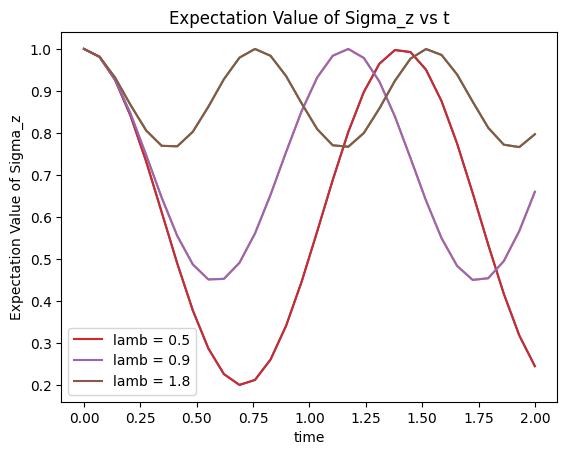

In [ ]:
from qiskit import QuantumCircuit, Aer, transpile, assemble
import numpy as np

from qiskit.primitives import Estimator

estimator = Estimator()

from qiskit.quantum_info import SparsePauliOp

observable=SparsePauliOp(['IZII', 'ZIII', 'IIIZ','IIZI'], coeffs=[0.25 +0.j,  0.25+0.j,  0.25 +0.j,  0.25 +0.j])

# Define a range of lambda values
#lambda_values = np.array([0.5,0.9,1.8])
lambda_values = np.array([0.5,0.9,1.8])
t_values = np.linspace(0, 2, 30)

# Simulate the circuit for each lambda value
expectation_values = []

expVals=np.zeros((len(t_values),len(lambda_values)))

for idx_lam,lambda_val in enumerate(lambda_values):
  print("lambda",lambda_val)
  for idx_t,t_val in enumerate(t_values):
    qc = create_circuit_6(lambda_val,t_val)

    # Use Aer simulator
    simulator = Aer.get_backend('qasm_simulator')
    transpiled_circuit = transpile(qc, simulator)
    result = simulator.run(assemble(transpiled_circuit)).result()
    #variables
    k=1
    n=4
    theta0 =np.arccos((lambda_val-np.cos(2*pi*0/n))/(np.sqrt((lambda_val-np.cos(2*pi*0/n))**2+np.sin(2*pi*0/n)**2)))
    theta1 =np.arccos((lambda_val-np.cos(2*pi*1/n))/(np.sqrt((lambda_val-np.cos(2*pi*k/n))**2+np.sin(2*pi*k/n)**2)))
    phi    =np.arccos(lambda_val/(np.sqrt(lambda_val**2+1)))/2
    phase  =4*t_val*np.sqrt(1+lambda_val**2)
    # Calculate and store the expectation value
    job =estimator.run(qc, observable)
    #expectation_value=float(job.result())
    #print(job.result())
    print(job.result().values[0])
    expectation_value=job.result().values[0]
    expectation_values.append(expectation_values)
    expVals[idx_t,idx_lam] = job.result().values[0]
    print("theta0",theta0)
    print("theta1",theta1)
    print("phi",phi)
    print("phase",phase)



# Plot the results
exparray=np.array([-5.55111512e-17,0.04585852,0.09058121,0.13316769,])
plt.figure(1)
plt.plot(t_values, expVals)
I0 = plt.plot(t_values, expVals[:,0])
I1 = plt.plot(t_values, expVals[:,1])
I2 = plt.plot(t_values, expVals[:,2])
plt.legend( (I0[0], I1[0], I2[0]), ("lamb = 0.5", "lamb = 0.9","lamb = 1.8"))

#plt.ylim([0,1])
plt.plot()
plt.xlabel('time')
plt.ylabel('Expectation Value of Sigma_z')
plt.title('Expectation Value of Sigma_z vs t')
plt.show()

Observable Mean: 0.46369379092396257
Observable Mean: 0.34318389468294896
Observable Mean: 0.19393488789391478
Observable Mean: 0.48175959242376004
Observable Mean: 0.2782544389794217
Observable Mean: 0.22479643769503804
Observable Mean: 0.4800246487464833
Observable Mean: 0.40311747069553383
Observable Mean: 0.32237577222981384


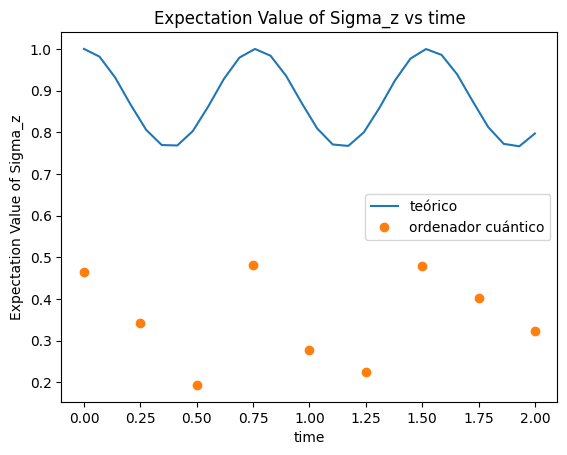

In [ ]:
# 2048 shots

# t= 0
mean_sigz_med_qyoto= np.zeros(9)
# Example: Use a quasi_dist array representing the measurement outcomes
#"quasi_dists":
[
    {
      "1000": 0.2948599956440951,
      "1001": -0.07715460009036898,
      "1010": -0.052330926421808185,
      "1011": 0.08258448304239083,
      "1100": 0.23660783835930133,
      "1101": -0.055702298771844794,
      "1110": -0.045451481772582195,
      "1111": 0.07506905689304963,
      "0000": 0.3934664968169015,
      "0001": -0.09438389559035879,
      "0010": -0.07199074816089769,
      "0011": 0.09701255387528418,
      "0100": 0.2069666930174911,
      "0101": -0.02663692818776589,
      "0110": -0.026344879065031534,
      "0111": 0.06342864041214441
    }
  ]

mean_sigz=((0.2948599956440951)+(-0.09438389559035879)+(-0.07199074816089769) + (0.2069666930174911))*2+\
 ((0.08258448304239083)+(-0.055702298771844794)+( -0.045451481772582195)+(0.06342864041214441))*(-2) +(0.3934664968169015)*4 + (0.07506905689304963)*-4

mean_sigz_med= 0.25*mean_sigz
mean_sigz_med_qyoto[0]=mean_sigz_med
print("Observable Mean:", mean_sigz_med)

# t= 0.25

# Example: Use a quasi_dist array representing the measurement outcomes
#"quasi_dists":
[
    {
      "1000": 0.22728139945621742,
      "1001": -0.08839248302956348,
      "1010": -0.057193338065821664,
      "1011": 0.15664004299791776,
      "1100": 0.18824861683123456,
      "1101": -0.06920239113641957,
      "1110": -0.05573515694745584,
      "1111": 0.10201747136583936,
      "0000": 0.3893254611301871,
      "0001": -0.052013955224916954,
      "0010": -0.08354322546494453,
      "0011": 0.15911828922921134,
      "0100": 0.11909883382254433,
      "0101": 0.006415006247494851,
      "0110": -0.009433319049180306,
      "0111": 0.06736874783765559
    }
  ]
mean_sigz=((0.22728139945621742)+(-0.052013955224916954)+(-0.08354322546494453) + (0.11909883382254433))*2+\
 ((0.15664004299791776)+(-0.06920239113641957)+(-0.05573515694745584)+(0.06736874783765559))*(-2) +( 0.3893254611301871)*4 + (0.10201747136583936)*-4

mean_sigz_med= 0.25*mean_sigz
mean_sigz_med_qyoto[1]=mean_sigz_med
print("Observable Mean:", mean_sigz_med)



# t= 0.5

# Example: Use a quasi_dist array representing the measurement outcomes

[
	{
		"1000": 0.21489208605105561,
		"1001": -0.046217988269287594,
		"1010": -0.05610548877195522,
		"1011": 0.19903999899565217,
		"1100": 0.16420495672959592,
		"1101": -0.0009899210824449419,
		"1110": -0.04548957034154543,
		"1111": 0.1044709242771323,
		"0000": 0.31936005877817847,
		"0001": -0.09937273339878983,
		"0010": -0.0699800561472526,
		"0011": 0.10751455252684422,
		"0100": 0.1712655256915596,
		"0101": -0.05880112939297871,
		"0110": -0.00994402348493766,
		"0111": 0.1061528078391738
	}
]
mean_sigz=(( 0.21489208605105561)+(-0.09937273339878983)+(-0.0699800561472526) + (0.1712655256915596))*2+\
 (( 0.19903999899565217)+(-0.0009899210824449419)+(-0.04548957034154543)+(0.1061528078391738))*(-2) +(0.31936005877817847)*4 + (0.1044709242771323)*-4

mean_sigz_med= 0.25*mean_sigz
mean_sigz_med_qyoto[2]=mean_sigz_med
print("Observable Mean:", mean_sigz_med)

#t = 0.75
# Example: Use a quasi_dist array representing the measurement outcomes

[
    {
      "1000": 0.31070850256494437,
      "1001": -0.04795227438222632,
      "1010": -0.05845715883436085,
      "1011": 0.08273761746160925,
      "1100": 0.2437141114157784,
      "1101": -0.06621559007867993,
      "1110": -0.047335477869245024,
      "1111": 0.10227240179321002,
      "0000": 0.39167645876759855,
      "0001": -0.08849697961332863,
      "0010": -0.05354484423364642,
      "0011": 0.05309983807168276,
      "0100": 0.20584211846570818,
      "0101": -0.032476936582329946,
      "0110": -0.016182963717964377,
      "0111": 0.020611176771250034
    }
  ]
mean_sigz=((0.31070850256494437)+(-0.08849697961332863)+(-0.05354484423364642) + (0.20584211846570818))*2+\
 ((0.08273761746160925)+(-0.06621559007867993)+(-0.047335477869245024)+(0.020611176771250034))*(-2) +(0.39167645876759855)*4 + ( 0.10227240179321002)*-4

mean_sigz_med= 0.25*mean_sigz
mean_sigz_med_qyoto[3]=mean_sigz_med
print("Observable Mean:", mean_sigz_med)

# t= 1
# Example: Use a quasi_dist array representing the measurement outcomes
 #"quasi_dists":
[
    {
      "1000": 0.2446575303864918,
      "1001": -0.04966256386404664,
      "1010": -0.01535178870168986,
      "1011": 0.11209370576488935,
      "1100": 0.12255910012646082,
      "1101": 0.008643459811336593,
      "1110": -0.006104488584826799,
      "1111": 0.0815023611740765,
      "0000": 0.3123376750059055,
      "0001": -0.04132766136369708,
      "0010": -0.09454121865635019,
      "0011": 0.13565671493825116,
      "0100": 0.18305385352353132,
      "0101": -0.04805275062239424,
      "0110": -0.027835505541329388,
      "0111": 0.08237157660339127
    }
  ]

mean_sigz=((0.2446575303864918)+(-0.04132766136369708)+(-0.09454121865635019) + (0.18305385352353132))*2+\
 ((0.11209370576488935)+(0.008643459811336593)+(-0.006104488584826799)+( 0.08237157660339127))*(-2) +(0.3123376750059055)*4 + (0.0815023611740765)*-4

mean_sigz_med= 0.25*mean_sigz
mean_sigz_med_qyoto[4]=mean_sigz_med
print("Observable Mean:", mean_sigz_med)


# t= 1.25

# Example: Use a quasi_dist array representing the measurement outcomes
 #"quasi_dists":
[
    {
      "1000": 0.24110959828884623,
      "1001": -0.06091284635487568,
      "1010": -0.03400992144919695,
      "1011": 0.13526282099555476,
      "1100": 0.1377485372291697,
      "1101": -0.021084490281883316,
      "1110": -0.025073552671574153,
      "1111": 0.12136693780883868,
      "0000": 0.3125905530948251,
      "0001": -0.03567547371355686,
      "0010": -0.07221693039657123,
      "0011": 0.12184543340561568,
      "0100": 0.11251396924966016,
      "0101": 0.011299576899501689,
      "0110": -0.034244952672531574,
      "0111": 0.08948074056817776
    }
  ]


mean_sigz=(( 0.24110959828884623)+(-0.03567547371355686)+(-0.07221693039657123) + (0.11251396924966016))*2+\
 ((0.13526282099555476)+(-0.021084490281883316)+(-0.025073552671574153)+(0.08948074056817776))*(-2) +(0.3125905530948251)*4 + (0.12136693780883868)*-4

mean_sigz_med= 0.25*mean_sigz
mean_sigz_med_qyoto[5]=mean_sigz_med
print("Observable Mean:", mean_sigz_med)


# t= 1.5

# Example: Use a quasi_dist array representing the measurement outcomes
# "quasi_dists":
[
    {
      "1000": 0.40995288193699625,
      "1001": -0.10694825464685775,
      "1010": -0.052879864758324235,
      "1011": 0.0857387061271805,
      "1100": 0.21392247110056567,
      "1101": -0.03401860732396692,
      "1110": -0.025842407520593073,
      "1111": 0.0535547082334521,
      "0000": 0.35745069998380447,
      "0001": -0.07508983369723166,
      "0010": -0.07671780093566372,
      "0011": 0.07936039535112614,
      "0100": 0.17830764787125847,
      "0101": -0.014243035536673545,
      "0110": -0.05086559608554975,
      "0111": 0.05831788990047695
    }
  ]

mean_sigz=((0.40995288193699625)+(-0.07508983369723166)+(-0.07671780093566372) + (0.17830764787125847))*2+\
 ((0.0857387061271805)+(-0.03401860732396692)+(-0.025842407520593073)+(0.05831788990047695))*(-2) +(0.35745069998380447)*4 + (0.0535547082334521)*-4

mean_sigz_med= 0.25*mean_sigz
mean_sigz_med_qyoto[6]=mean_sigz_med
print("Observable Mean:", mean_sigz_med)

# t= 1.75
# Example: Use a quasi_dist array representing the measurement outcomes
#
[
    {
      "1000": 0.31596717122897106,
      "1001": -0.11978940295262597,
      "1010": -0.06824863579670007,
      "1011": 0.14374703719049783,
      "1100": 0.16656736859644505,
      "1101": -0.031709072894828626,
      "1110": -0.042166023270253296,
      "1111": 0.08465070266726596,
      "0000": 0.34919530260967985,
      "0001": -0.014683513040265076,
      "0010": -0.06657063967491132,
      "0011": 0.11268008000203236,
      "0100": 0.16400508386874696,
      "0101": -0.029706661292306324,
      "0110": -0.015639217092634442,
      "0111": 0.05170041985088591
    }
  ]

mean_sigz=((0.31596717122897106)+(-0.014683513040265076)+( -0.06657063967491132) + (0.16400508386874696))*2+\
 ((0.14374703719049783)+(-0.031709072894828626)+(-0.042166023270253296)+(0.05170041985088591))*(-2) +(0.34919530260967985)*4 + (0.08465070266726596)*-4

mean_sigz_med= 0.25*mean_sigz
mean_sigz_med_qyoto[7]=mean_sigz_med
print("Observable Mean:", mean_sigz_med)

# t= 2

# Example: Use a quasi_dist array representing the measurement outcomes
[
    {
      "1000": 0.27205423936957496,
      "1001": -0.09891030499034324,
      "1010": -0.010945588516198968,
      "1011": 0.11097601215172702,
      "1100": 0.1593412241635223,
      "1101": -0.03416311682034511,
      "1110": -0.0047277551108810415,
      "1111": 0.06834962721488715,
      "0000": 0.3262723547886908,
      "0001": -0.04726021519190751,
      "0010": -0.06577408304467959,
      "0011": 0.1451709466151353,
      "0100": 0.10989786735064168,
      "0101": 0.0028394685452110906,
      "0110": -0.0010472554761431269,
      "0111": 0.06792657895110839
    }
  ]

mean_sigz=((0.27205423936957496)+(-0.04726021519190751)+(-0.06577408304467959) + (0.10989786735064168))*2+\
 (( 0.11097601215172702)+(-0.03416311682034511)+(-0.0047277551108810415)+( 0.06792657895110839))*(-2) +(0.3262723547886908)*4 + (0.06834962721488715)*-4

mean_sigz_med= 0.25*mean_sigz
mean_sigz_med_qyoto[8]=mean_sigz_med
print("Observable Mean:", mean_sigz_med)


t_values2 = np.linspace(0,2,9)
#I0 = plt.plot(t_values, expVals[:,0])
#I1 = plt.plot(t_values, expValsx[:,1])
I2 = plt.plot(t_values, expVals[:,2])
#plt.legend( (I0[0], I1[0], I2[0]), ("lamb = 0.5", "lamb = 0.9","lamb = 1.8"))

#plt.ylim([0,1])
plt.title('Expectation Value of Sigma_z vs t')
I1 = plt.plot(t_values2,mean_sigz_med_qyoto,'o')
#plt.ylim([0,1.3])
plt.xlabel('time')
plt.ylabel('Expectation Value of Sigma_z')
plt.title('Expectation Value of Sigma_z vs time')
plt.legend( (I2[0],I1[0]), ("teórico","ordenador cuántico"))
plt.show()

Observable Mean: 0.42531133686673606
Observable Mean: 0.35557704598409207
Observable Mean: -0.13213570556105228
Observable Mean: -0.3233490778065662
Observable Mean: -0.06397122499367791
Observable Mean: 0.2847460578114988
Observable Mean: 0.4163862954138847
Observable Mean: 0.25085895412704984
Observable Mean: -0.174774450646465


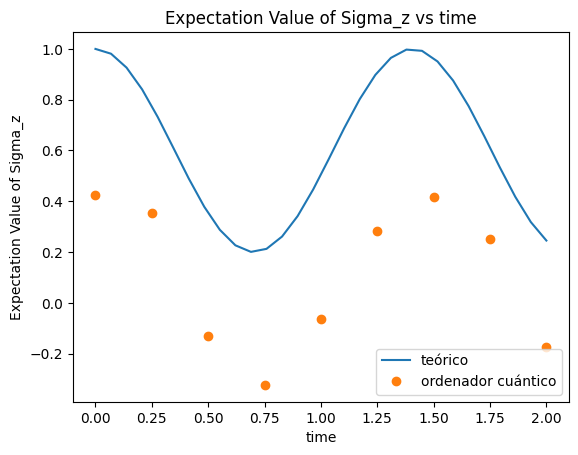

In [ ]:
# t= 0
mean_sigz_med_qyoto= np.zeros(9)
# Example: Use a quasi_dist array representing the measurement outcomes
#"quasi_dists":
[
	{
		"1000": 0.2650078294968683,
		"1001": -0.050768183900813245,
		"1010": -0.031418471460772486,
		"1011": 0.07542609086236819,
		"1100": 0.19353035920534623,
		"1101": -0.015488710541032666,
		"1110": -0.02451403241912712,
		"1111": 0.04891422816398132,
		"0000": 0.4022431114901538,
		"0001": -0.13079318249830643,
		"0010": -0.049118147417573324,
		"0011": 0.10984162260360056,
		"0100": 0.1875878403088532,
		"0101": -0.03080736393622027,
		"0110": -0.04293907486383232,
		"0111": 0.09329608490650616
	}
]

mean_sigz=((0.2650078294968683)+(-0.13079318249830643)+(-0.049118147417573324) + (0.1875878403088532))*2+\
 ((0.07542609086236819)+(-0.015488710541032666)+(-0.02451403241912712)+(0.09329608490650616))*(-2) +( 0.4022431114901538)*4 + (0.04891422816398132)*-4

mean_sigz_med= 0.25*mean_sigz
mean_sigz_med_qyoto[0]=mean_sigz_med
print("Observable Mean:", mean_sigz_med)

#t= 0.25
# Example: Use a quasi_dist array representing the measurement outcomes
#"quasi_dists":
[
	{
		"1000": 0.2292098788391147,
		"1001": -0.03907784991897571,
		"1010": -0.05370334173277631,
		"1011": 0.11122049910579569,
		"1100": 0.08356594788522179,
		"1101": -0.007455019056843948,
		"1110": 0.011716288848918885,
		"1111": 0.057775274629254435,
		"0000": 0.42552162816335753,
		"0001": -0.12557025343692796,
		"0010": -0.07592754109545932,
		"0011": 0.180799967020406,
		"0100": 0.12776745570525896,
		"0101": 0.024836817585941723,
		"0110": -0.015016138756424387,
		"0111": 0.06433638621413781
	}
]

mean_sigz=((0.2292098788391147)+(-0.12557025343692796)+(-0.07592754109545932) + (0.12776745570525896))*2+\
 ((0.11122049910579569)+( -0.007455019056843948)+(0.011716288848918885)+(0.06433638621413781))*(-2) +( 0.42552162816335753)*4 + (0.057775274629254435)*-4

mean_sigz_med= 0.25*mean_sigz
mean_sigz_med_qyoto[1]=mean_sigz_med
print("Observable Mean:", mean_sigz_med)


# t= 0.5

# Example: Use a quasi_dist array representing the measurement outcomes
#"quasi_dists":
[
    {
      "1000": 0.21570164652751814,
      "1001": -0.1114802047140634,
      "1010": -0.0895889656192231,
      "1011": 0.29718982937276184,
      "1100": 0.10444473052232793,
      "1101": 0.004450166295670898,
      "1110": -0.028485270219645933,
      "1111": 0.15088239720421467,
      "0000": 0.1405068643565574,
      "0001": -0.062444149337518,
      "0010": -0.1086822149207607,
      "0011": 0.3402370433003588,
      "0100": 0.08143633863748223,
      "0101": -0.018082763641101982,
      "0110": -0.01246268864930362,
      "0111": 0.09637724088472485
    }
  ]
mean_sigz=((0.21570164652751814)+(-0.062444149337518)+(-0.1086822149207607) + (0.08143633863748223))*2+\
 ((0.29718982937276184)+(0.004450166295670898)+(-0.028485270219645933)+(0.09637724088472485))*(-2) +(0.1405068643565574)*4 + (0.15088239720421467)*-4

mean_sigz_med= 0.25*mean_sigz
mean_sigz_med_qyoto[2]=mean_sigz_med
print("Observable Mean:", mean_sigz_med)



# t= 0.75

# Example: Use a quasi_dist array representing the measurement outcomes

[
    {
      "1000": 0.05696849387058076,
      "1001": -0.050404869670024256,
      "1010": -0.05950084999416002,
      "1011": 0.35025435630970664,
      "1100": 0.019197070120675935,
      "1101": -0.012153651000934032,
      "1110": -0.0033580470186678184,
      "1111": 0.17016477057171922,
      "0000": 0.1171165358489084,
      "0001": -0.06040278469410795,
      "0010": -0.1328698734258734,
      "0011": 0.4463364032566594,
      "0100": 0.06571419077052044,
      "0101": -0.004356677704552389,
      "0110": -0.03797412163897688,
      "0111": 0.13526905439852588
    }
  ]
mean_sigz=(( 0.05696849387058076)+(-0.06040278469410795)+(-0.1328698734258734) + ( 0.06571419077052044))*2+\
 ((0.35025435630970664)+(-0.012153651000934032)+(-0.0033580470186678184)+(0.13526905439852588))*(-2) +(0.1171165358489084)*4 + (0.17016477057171922)*-4

mean_sigz_med= 0.25*mean_sigz
mean_sigz_med_qyoto[3]=mean_sigz_med
print("Observable Mean:", mean_sigz_med)

# t= 1
# Example: Use a quasi_dist array representing the measurement outcomes
 #"quasi_dists":
[
    {
      "1000": 0.08914399163727375,
      "1001": -0.004934592899013454,
      "1010": -0.0374476456341406,
      "1011": 0.26771977055650015,
      "1100": 0.09979390702476225,
      "1101": -0.024875840114211827,
      "1110": -0.01955266107572677,
      "1111": 0.14513034910552142,
      "0000": 0.2545690537921002,
      "0001": -0.1024350500546268,
      "0010": -0.08112397526973379,
      "0011": 0.2551557314688462,
      "0100": 0.06621431833150454,
      "0101": 0.001371249489377271,
      "0110": -0.004056480996802052,
      "0111": 0.0953278746383695
    }
  ]

mean_sigz=((0.08914399163727375)+(-0.1024350500546268)+(-0.08112397526973379) + (0.06621431833150454))*2+\
 ((0.26771977055650015)+(-0.024875840114211827)+(-0.01955266107572677)+(0.0953278746383695))*(-2) +(0.2545690537921002)*4 + (0.14513034910552142)*-4

mean_sigz_med= 0.25*mean_sigz
mean_sigz_med_qyoto[4]=mean_sigz_med
print("Observable Mean:", mean_sigz_med)

# t= 1.25

# Example: Use a quasi_dist array representing the measurement outcomes
# "quasi_dists":
[
    {
      "1000": 0.24010330628469204,
      "1001": -0.05559938711561305,
      "1010": -0.06336148814416749,
      "1011": 0.13044855305580336,
      "1100": 0.14449647839511007,
      "1101": -0.008601797260724499,
      "1110": -0.011260988625364187,
      "1111": 0.035068960600693325,
      "0000": 0.3554240701103442,
      "0001": -0.04628289475194874,
      "0010": -0.03684121694064356,
      "0011": 0.10508147692617147,
      "0100": 0.1551713844956127,
      "0101": -0.01730957153417081,
      "0110": -0.007307199373840623,
      "0111": 0.08077031387804569
    }
  ]

mean_sigz=((0.24010330628469204)+(-0.04628289475194874)+(-0.03684121694064356) + (-0.03684121694064356))*2+\
 ((0.13044855305580336)+(-0.008601797260724499)+(-0.011260988625364187)+(0.08077031387804569))*(-2) +(0.3554240701103442)*4 + (0.035068960600693325)*-4

mean_sigz_med= 0.25*mean_sigz
mean_sigz_med_qyoto[5]=mean_sigz_med
print("Observable Mean:", mean_sigz_med)
# t= 1.5

# Example: Use a quasi_dist array representing the measurement outcomes
 #"quasi_dists":
[
	{
		"1000": 0.2952252175523708,
		"1001": -0.052899102987364874,
		"1010": -0.039362469282540724,
		"1011": 0.05789688723617842,
		"1100": 0.1446991024103144,
		"1101": -0.033533094626882254,
		"1110": -0.046170433007744795,
		"1111": 0.09540666133889054,
		"0000": 0.39676811411842505,
		"0001": -0.0787019378151638,
		"0010": -0.10641974781470277,
		"0011": 0.16993201210020312,
		"0100": 0.13790560937675014,
		"0101": 0.009111739712257129,
		"0110": 0.010375345260006974,
		"0111": 0.039766096429002556
	}
]

mean_sigz=((0.2952252175523708)+(-0.0787019378151638)+(-0.10641974781470277) + ( 0.13790560937675014))*2+\
 ((0.05789688723617842)+(-0.033533094626882254)+(-0.046170433007744795)+( 0.039766096429002556))*(-2) +(0.39676811411842505)*4 + (0.09540666133889054)*-4

mean_sigz_med= 0.25*mean_sigz
mean_sigz_med_qyoto[6]=mean_sigz_med
print("Observable Mean:", mean_sigz_med)


# t= 1.75

# Example: Use a quasi_dist array representing the measurement outcomes
[
    {
      "1000": 0.2199378264393174,
      "1001": -0.02569756668474913,
      "1010": -0.055171104228621586,
      "1011": 0.12653528485348467,
      "1100": 0.10650805386284909,
      "1101": -0.02281889075215008,
      "1110": -0.04818502718505463,
      "1111": 0.08898253780328944,
      "0000": 0.35386561287109364,
      "0001": -0.09842803104243474,
      "0010": -0.11014726200975289,
      "0011": 0.3227057634458279,
      "0100": 0.0924272005424551,
      "0101": -0.006318353058407757,
      "0110": -0.02050265375196017,
      "0111": 0.0763066088948137
    }
  ]

mean_sigz=((0.2199378264393174)+(-0.09842803104243474)+(-0.11014726200975289) + (0.0924272005424551))*2+\
 ((0.12653528485348467)+(-0.02281889075215008)+(-0.04818502718505463)+(0.0763066088948137))*(-2) +(0.35386561287109364)*4 + (0.08898253780328944)*-4

mean_sigz_med= 0.25*mean_sigz
mean_sigz_med_qyoto[7]=mean_sigz_med
print("Observable Mean:", mean_sigz_med)

# t= 2

# Example: Use a quasi_dist array representing the measurement outcomes
[
    {
      "1000": 0.10534105165918277,
      "1001": -0.06379735575676539,
      "1010": -0.06942153439107547,
      "1011": 0.30317756838231597,
      "1100": 0.03730869281460948,
      "1101": -0.005368436463120518,
      "1110": -0.033598568497387286,
      "1111": 0.13280846412385497,
      "0000": 0.1386893118753576,
      "0001": -0.04276568214291449,
      "0010": -0.09392502144600799,
      "0011": 0.45804700971274653,
      "0100": 0.017614307658797023,
      "0101": 0.029832433937737674,
      "0110": 0.002693069429484575,
      "0111": 0.08336468910318441
    }
  ]

mean_sigz=((0.10534105165918277)+(-0.04276568214291449)+(-0.09392502144600799) + (0.017614307658797023))*2+\
 ((0.30317756838231597)+(-0.005368436463120518)+(-0.033598568497387286)+(0.08336468910318441))*(-2) +(0.1386893118753576)*4 + (0.13280846412385497)*-4

mean_sigz_med= 0.25*mean_sigz
mean_sigz_med_qyoto[8]=mean_sigz_med
print("Observable Mean:", mean_sigz_med)

t_values2 = np.linspace(0,2,9)
I0 = plt.plot(t_values, expVals[:,0])
#I1 = plt.plot(t_values, expValsx[:,1])
#I2 = plt.plot(t_values, expVals[:,2])
#plt.legend( (I0[0], I1[0], I2[0]), ("lamb = 0.5", "lamb = 0.9","lamb = 1.8"))

#plt.ylim([0,1])
plt.title('Expectation Value of Sigma_z vs t')
I1 = plt.plot(t_values2,mean_sigz_med_qyoto,'o')
#plt.ylim([0,1.3])
plt.xlabel('time')
plt.ylabel('Expectation Value of Sigma_z')
plt.title('Expectation Value of Sigma_z vs time')
plt.legend( (I0[0],I1[0]), ("teórico","ordenador cuántico"))
plt.show()

Para toda lambda

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from qiskit import QuantumCircuit, Aer, transpile, assemble, QuantumRegister, ClassicalRegister
from qiskit.visualization import plot_histogram
from numpy import pi

# Function to create the quantum circuit
def create_circuit_6(lamb,t):
    qreg_q = QuantumRegister(4, 'q')
    circuit = QuantumCircuit(qreg_q)
    initial_state = [1, 0, 0, 0,0,0,0,0,0,0,0,0,0,0,0,0]
    # Amplitude for |0000⟩ is 1, all others are 0
    # Initialize the quantum circuit to the desired state
    circuit.initialize(initial_state, circuit.qubits)

    #variables
    k=1
    n=4
    theta0 =np.arccos((lamb-np.cos(2*pi*0/n))/(np.sqrt((lamb-np.cos(2*pi*0/n))**2+np.sin(2*pi*0/n)**2)))
    theta1 =np.arccos((lamb-np.cos(2*pi*1/n))/(np.sqrt((lamb-np.cos(2*pi*k/n))**2+np.sin(2*pi*k/n)**2)))
#    phi    =np.arccos(lamb/(np.sqrt(lamb**2+1)))/2
    phase  =4*t*np.sqrt(1+lamb**2)


    circuit.ry(theta1 , qreg_q[0])
    circuit.u(0, 0, phase + pi/2, qreg_q[0])
    circuit.cx(qreg_q[0], qreg_q[1])
    circuit.ry(theta0 , qreg_q[2])
    circuit.u(0, 0, phase+ pi/2, qreg_q[2])
    circuit.cx(qreg_q[2], qreg_q[3])
#    circuit.ry(phi, qreg_q[2])
#    circuit.u(0, 0, phase, qreg_q[2])
#    circuit.cx(qreg_q[2], qreg_q[3])
    circuit.x(qreg_q[1])
    circuit.x(qreg_q[3])
    circuit.cx(qreg_q[1], qreg_q[0])
    circuit.cx(qreg_q[3], qreg_q[2])
    circuit.rz(pi / 2, qreg_q[1])
    circuit.rz(pi / 2, qreg_q[3])
    circuit.cx(qreg_q[0], qreg_q[1])
    circuit.cx(qreg_q[2], qreg_q[3])
    circuit.ry(-theta1 / 2, qreg_q[1])
# here we have +pi/2 as it is the transpose conjugate
    circuit.ry(-theta0 / 2, qreg_q[3])
    circuit.cx(qreg_q[0], qreg_q[1])
    circuit.cx(qreg_q[2], qreg_q[3])
    circuit.ry(theta1 / 2, qreg_q[1])
    circuit.ry(theta0 / 2, qreg_q[3])
    circuit.rz(-pi / 2, qreg_q[1])
    circuit.rz(-pi / 2, qreg_q[3])
    circuit.cx(qreg_q[1], qreg_q[0])
    circuit.cx(qreg_q[3], qreg_q[2])
    circuit.x(qreg_q[1])
    circuit.x(qreg_q[3])
    circuit.cz(qreg_q[0], qreg_q[1])
    circuit.cz(qreg_q[2], qreg_q[3])
    circuit.cx(qreg_q[0], qreg_q[1])
    circuit.cx(qreg_q[2], qreg_q[3])
    #ch's to be changed
    circuit.h(qreg_q[0])
    circuit.cx(qreg_q[1], qreg_q[0])
    circuit.h(qreg_q[0])

    circuit.h(qreg_q[2])
    circuit.cx(qreg_q[3], qreg_q[2])
    circuit.h(qreg_q[2])

    circuit.cx(qreg_q[0], qreg_q[1])
    circuit.cx(qreg_q[2], qreg_q[3])
    circuit.u(0, 0, -2 * pi / 4, qreg_q[0])
    circuit.u(0, 0, 0, qreg_q[2])
    circuit.cx(qreg_q[1], qreg_q[2])
    circuit.cx(qreg_q[2], qreg_q[1])
    circuit.cx(qreg_q[1], qreg_q[2])
    circuit.h(qreg_q[2])
    circuit.cx(qreg_q[1], qreg_q[2])
    circuit.h(qreg_q[2])
    circuit.cz(qreg_q[0], qreg_q[1])
    circuit.cx(qreg_q[0], qreg_q[1])
    circuit.cz(qreg_q[2], qreg_q[3])

    circuit.h(qreg_q[0])
    circuit.cx(qreg_q[1], qreg_q[0])
    circuit.h(qreg_q[0])
    circuit.cx(qreg_q[2], qreg_q[3])
    circuit.cx(qreg_q[0], qreg_q[1])
    circuit.h(qreg_q[2])
    circuit.cx(qreg_q[3], qreg_q[2])
    circuit.h(qreg_q[2])

    circuit.u(0, 0, 0, qreg_q[0])
    circuit.cx(qreg_q[2], qreg_q[3])
    circuit.u(0, 0, 0, qreg_q[2])
    circuit.cx(qreg_q[1], qreg_q[2])
    circuit.cx(qreg_q[2], qreg_q[1])
    circuit.cx(qreg_q[1], qreg_q[2])
    circuit.h(qreg_q[2])
    circuit.cx(qreg_q[1], qreg_q[2])
    circuit.h(qreg_q[2])

    # Apply gates based on the lambda parameter
    # Modify this part based on your specific circuit

    # Measure all qubits
    #circuit.measure_all()

    return circuit

lambda 0.5
0.999999999999998
theta0 3.141592653589793
theta1 1.1071487177940906
phi 0.5535743588970452
phase 0.0
0.9811253646271956
theta0 3.141592653589793
theta1 1.1071487177940906
phi 0.5535743588970452
phase 0.3084231693103158
0.9262827178110702
theta0 3.141592653589793
theta1 1.1071487177940906
phi 0.5535743588970452
phase 0.6168463386206317
0.8406477343592906
theta0 3.141592653589793
theta1 1.1071487177940906
phi 0.5535743588970452
phase 0.9252695079309475


<ipython-input-12-e3248e636411>:30: DeprecationWarning: Using a qobj for run() is deprecated as of qiskit-aer 0.9.0 and will be removed no sooner than 3 months from that release date. Transpiled circuits should now be passed directly using `backend.run(circuits, **run_options).
  result = simulator.run(assemble(transpiled_circuit)).result()


0.7323020597108982
theta0 3.141592653589793
theta1 1.1071487177940906
phi 0.5535743588970452
phase 1.2336926772412633
0.6114706193819373
theta0 3.141592653589793
theta1 1.1071487177940906
phi 0.5535743588970452
phase 1.5421158465515792
0.4895566602613024
theta0 3.141592653589793
theta1 1.1071487177940906
phi 0.5535743588970452
phase 1.850539015861895
0.37806558997528106
theta0 3.141592653589793
theta1 1.1071487177940906
phi 0.5535743588970452
phase 2.1589621851722107
0.2875191750187317
theta0 3.141592653589793
theta1 1.1071487177940906
phi 0.5535743588970452
phase 2.4673853544825266
0.22646256822475216
theta0 3.141592653589793
theta1 1.1071487177940906
phi 0.5535743588970452
phase 2.7758085237928425
0.20065787554502582
theta0 3.141592653589793
theta1 1.1071487177940906
phi 0.5535743588970452
phase 3.0842316931031584
0.2125403678057384
theta0 3.141592653589793
theta1 1.1071487177940906
phi 0.5535743588970452
phase 3.392654862413474
0.2609886564631847
theta0 3.141592653589793
theta1 1.10

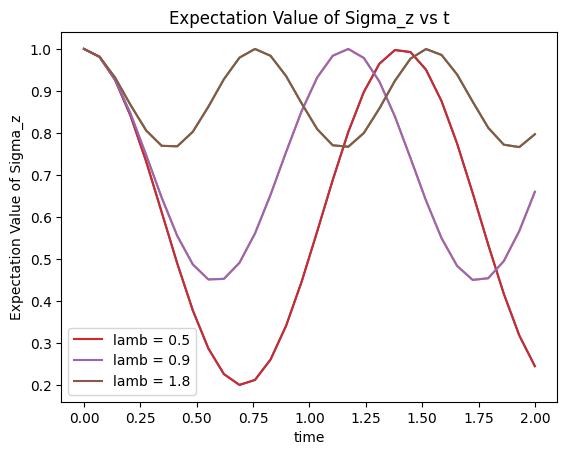

In [ ]:
from qiskit import QuantumCircuit, Aer, transpile, assemble
import numpy as np

from qiskit.primitives import Estimator

estimator = Estimator()

from qiskit.quantum_info import SparsePauliOp

observable=SparsePauliOp(['IZII', 'ZIII', 'IIIZ','IIZI'], coeffs=[0.25 +0.j,  0.25+0.j,  0.25 +0.j,  0.25 +0.j])

# Define a range of lambda values
#lambda_values = np.array([0.5,0.9,1.8])
lambda_values = np.array([0.5,0.9,1.8])
t_values = np.linspace(0, 2, 30)

# Simulate the circuit for each lambda value
expectation_values = []

expVals=np.zeros((len(t_values),len(lambda_values)))

for idx_lam,lambda_val in enumerate(lambda_values):
  print("lambda",lambda_val)
  for idx_t,t_val in enumerate(t_values):
    qc = create_circuit_6(lambda_val,t_val)

    # Use Aer simulator
    simulator = Aer.get_backend('qasm_simulator')
    transpiled_circuit = transpile(qc, simulator)
    result = simulator.run(assemble(transpiled_circuit)).result()
    #variables
    k=1
    n=4
    theta0 =np.arccos((lambda_val-np.cos(2*pi*0/n))/(np.sqrt((lambda_val-np.cos(2*pi*0/n))**2+np.sin(2*pi*0/n)**2)))
    theta1 =np.arccos((lambda_val-np.cos(2*pi*1/n))/(np.sqrt((lambda_val-np.cos(2*pi*k/n))**2+np.sin(2*pi*k/n)**2)))
    phi    =np.arccos(lambda_val/(np.sqrt(lambda_val**2+1)))/2
    phase  =4*t_val*np.sqrt(1+lambda_val**2)
    # Calculate and store the expectation value
    job =estimator.run(qc, observable)
    #expectation_value=float(job.result())
    #print(job.result())
    print(job.result().values[0])
    expectation_value=job.result().values[0]
    expectation_values.append(expectation_values)
    expVals[idx_t,idx_lam] = job.result().values[0]
    print("theta0",theta0)
    print("theta1",theta1)
    print("phi",phi)
    print("phase",phase)



# Plot the results
exparray=np.array([-5.55111512e-17,0.04585852,0.09058121,0.13316769,])
plt.figure(1)
plt.plot(t_values, expVals)
I0 = plt.plot(t_values, expVals[:,0])
I1 = plt.plot(t_values, expVals[:,1])
I2 = plt.plot(t_values, expVals[:,2])
plt.legend( (I0[0], I1[0], I2[0]), ("lamb = 0.5", "lamb = 0.9","lamb = 1.8"))

#plt.ylim([0,1])
plt.plot()
plt.xlabel('time')
plt.ylabel('Expectation Value of Sigma_z')
plt.title('Expectation Value of Sigma_z vs t')
plt.show()

In [ ]:
# 2048 shots

# t= 0
mean_sigz_med_qyoto= np.zeros(9)
# Example: Use a quasi_dist array representing the measurement outcomes
#"quasi_dists":
[
    {
      "1000": 0.2948599956440951,
      "1001": -0.07715460009036898,
      "1010": -0.052330926421808185,
      "1011": 0.08258448304239083,
      "1100": 0.23660783835930133,
      "1101": -0.055702298771844794,
      "1110": -0.045451481772582195,
      "1111": 0.07506905689304963,
      "0000": 0.3934664968169015,
      "0001": -0.09438389559035879,
      "0010": -0.07199074816089769,
      "0011": 0.09701255387528418,
      "0100": 0.2069666930174911,
      "0101": -0.02663692818776589,
      "0110": -0.026344879065031534,
      "0111": 0.06342864041214441
    }
  ]

mean_sigz=((0.2948599956440951)+(-0.09438389559035879)+(-0.07199074816089769) + (0.2069666930174911))*2+\
 ((0.08258448304239083)+(-0.055702298771844794)+( -0.045451481772582195)+(0.06342864041214441))*(-2) +(0.3934664968169015)*4 + (0.07506905689304963)*-4

mean_sigz_med= 0.25*mean_sigz
mean_sigz_med_qyoto[0]=mean_sigz_med
print("Observable Mean:", mean_sigz_med)

# t= 0.25

# Example: Use a quasi_dist array representing the measurement outcomes
#"quasi_dists":
[
    {
      "1000": 0.22728139945621742,
      "1001": -0.08839248302956348,
      "1010": -0.057193338065821664,
      "1011": 0.15664004299791776,
      "1100": 0.18824861683123456,
      "1101": -0.06920239113641957,
      "1110": -0.05573515694745584,
      "1111": 0.10201747136583936,
      "0000": 0.3893254611301871,
      "0001": -0.052013955224916954,
      "0010": -0.08354322546494453,
      "0011": 0.15911828922921134,
      "0100": 0.11909883382254433,
      "0101": 0.006415006247494851,
      "0110": -0.009433319049180306,
      "0111": 0.06736874783765559
    }
  ]
mean_sigz=((0.22728139945621742)+(-0.052013955224916954)+(-0.08354322546494453) + (0.11909883382254433))*2+\
 ((0.15664004299791776)+(-0.06920239113641957)+(-0.05573515694745584)+(0.06736874783765559))*(-2) +( 0.3893254611301871)*4 + (0.10201747136583936)*-4

mean_sigz_med= 0.25*mean_sigz
mean_sigz_med_qyoto[1]=mean_sigz_med
print("Observable Mean:", mean_sigz_med)



# t= 0.5

# Example: Use a quasi_dist array representing the measurement outcomes

[
	{
		"1000": 0.21489208605105561,
		"1001": -0.046217988269287594,
		"1010": -0.05610548877195522,
		"1011": 0.19903999899565217,
		"1100": 0.16420495672959592,
		"1101": -0.0009899210824449419,
		"1110": -0.04548957034154543,
		"1111": 0.1044709242771323,
		"0000": 0.31936005877817847,
		"0001": -0.09937273339878983,
		"0010": -0.0699800561472526,
		"0011": 0.10751455252684422,
		"0100": 0.1712655256915596,
		"0101": -0.05880112939297871,
		"0110": -0.00994402348493766,
		"0111": 0.1061528078391738
	}
]
mean_sigz=(( 0.21489208605105561)+(-0.09937273339878983)+(-0.0699800561472526) + (0.1712655256915596))*2+\
 (( 0.19903999899565217)+(-0.0009899210824449419)+(-0.04548957034154543)+(0.1061528078391738))*(-2) +(0.31936005877817847)*4 + (0.1044709242771323)*-4

mean_sigz_med= 0.25*mean_sigz
mean_sigz_med_qyoto[2]=mean_sigz_med
print("Observable Mean:", mean_sigz_med)

#t = 0.75
# Example: Use a quasi_dist array representing the measurement outcomes

[
    {
      "1000": 0.31070850256494437,
      "1001": -0.04795227438222632,
      "1010": -0.05845715883436085,
      "1011": 0.08273761746160925,
      "1100": 0.2437141114157784,
      "1101": -0.06621559007867993,
      "1110": -0.047335477869245024,
      "1111": 0.10227240179321002,
      "0000": 0.39167645876759855,
      "0001": -0.08849697961332863,
      "0010": -0.05354484423364642,
      "0011": 0.05309983807168276,
      "0100": 0.20584211846570818,
      "0101": -0.032476936582329946,
      "0110": -0.016182963717964377,
      "0111": 0.020611176771250034
    }
  ]
mean_sigz=((0.31070850256494437)+(-0.08849697961332863)+(-0.05354484423364642) + (0.20584211846570818))*2+\
 ((0.08273761746160925)+(-0.06621559007867993)+(-0.047335477869245024)+(0.020611176771250034))*(-2) +(0.39167645876759855)*4 + ( 0.10227240179321002)*-4

mean_sigz_med= 0.25*mean_sigz
mean_sigz_med_qyoto[3]=mean_sigz_med
print("Observable Mean:", mean_sigz_med)

# t= 1
# Example: Use a quasi_dist array representing the measurement outcomes
 #"quasi_dists":
[
    {
      "1000": 0.2446575303864918,
      "1001": -0.04966256386404664,
      "1010": -0.01535178870168986,
      "1011": 0.11209370576488935,
      "1100": 0.12255910012646082,
      "1101": 0.008643459811336593,
      "1110": -0.006104488584826799,
      "1111": 0.0815023611740765,
      "0000": 0.3123376750059055,
      "0001": -0.04132766136369708,
      "0010": -0.09454121865635019,
      "0011": 0.13565671493825116,
      "0100": 0.18305385352353132,
      "0101": -0.04805275062239424,
      "0110": -0.027835505541329388,
      "0111": 0.08237157660339127
    }
  ]

mean_sigz=((0.2446575303864918)+(-0.04132766136369708)+(-0.09454121865635019) + (0.18305385352353132))*2+\
 ((0.11209370576488935)+(0.008643459811336593)+(-0.006104488584826799)+( 0.08237157660339127))*(-2) +(0.3123376750059055)*4 + (0.0815023611740765)*-4

mean_sigz_med= 0.25*mean_sigz
mean_sigz_med_qyoto[4]=mean_sigz_med
print("Observable Mean:", mean_sigz_med)


# t= 1.25

# Example: Use a quasi_dist array representing the measurement outcomes
 #"quasi_dists":
[
    {
      "1000": 0.24110959828884623,
      "1001": -0.06091284635487568,
      "1010": -0.03400992144919695,
      "1011": 0.13526282099555476,
      "1100": 0.1377485372291697,
      "1101": -0.021084490281883316,
      "1110": -0.025073552671574153,
      "1111": 0.12136693780883868,
      "0000": 0.3125905530948251,
      "0001": -0.03567547371355686,
      "0010": -0.07221693039657123,
      "0011": 0.12184543340561568,
      "0100": 0.11251396924966016,
      "0101": 0.011299576899501689,
      "0110": -0.034244952672531574,
      "0111": 0.08948074056817776
    }
  ]


mean_sigz=(( 0.24110959828884623)+(-0.03567547371355686)+(-0.07221693039657123) + (0.11251396924966016))*2+\
 ((0.13526282099555476)+(-0.021084490281883316)+(-0.025073552671574153)+(0.08948074056817776))*(-2) +(0.3125905530948251)*4 + (0.12136693780883868)*-4

mean_sigz_med= 0.25*mean_sigz
mean_sigz_med_qyoto[5]=mean_sigz_med
print("Observable Mean:", mean_sigz_med)


# t= 1.5

# Example: Use a quasi_dist array representing the measurement outcomes
# "quasi_dists":
[
    {
      "1000": 0.40995288193699625,
      "1001": -0.10694825464685775,
      "1010": -0.052879864758324235,
      "1011": 0.0857387061271805,
      "1100": 0.21392247110056567,
      "1101": -0.03401860732396692,
      "1110": -0.025842407520593073,
      "1111": 0.0535547082334521,
      "0000": 0.35745069998380447,
      "0001": -0.07508983369723166,
      "0010": -0.07671780093566372,
      "0011": 0.07936039535112614,
      "0100": 0.17830764787125847,
      "0101": -0.014243035536673545,
      "0110": -0.05086559608554975,
      "0111": 0.05831788990047695
    }
  ]

mean_sigz=((0.40995288193699625)+(-0.07508983369723166)+(-0.07671780093566372) + (0.17830764787125847))*2+\
 ((0.0857387061271805)+(-0.03401860732396692)+(-0.025842407520593073)+(0.05831788990047695))*(-2) +(0.35745069998380447)*4 + (0.0535547082334521)*-4

mean_sigz_med= 0.25*mean_sigz
mean_sigz_med_qyoto[6]=mean_sigz_med
print("Observable Mean:", mean_sigz_med)

# t= 1.75
# Example: Use a quasi_dist array representing the measurement outcomes
#
[
    {
      "1000": 0.31596717122897106,
      "1001": -0.11978940295262597,
      "1010": -0.06824863579670007,
      "1011": 0.14374703719049783,
      "1100": 0.16656736859644505,
      "1101": -0.031709072894828626,
      "1110": -0.042166023270253296,
      "1111": 0.08465070266726596,
      "0000": 0.34919530260967985,
      "0001": -0.014683513040265076,
      "0010": -0.06657063967491132,
      "0011": 0.11268008000203236,
      "0100": 0.16400508386874696,
      "0101": -0.029706661292306324,
      "0110": -0.015639217092634442,
      "0111": 0.05170041985088591
    }
  ]

mean_sigz=((0.31596717122897106)+(-0.014683513040265076)+( -0.06657063967491132) + (0.16400508386874696))*2+\
 ((0.14374703719049783)+(-0.031709072894828626)+(-0.042166023270253296)+(0.05170041985088591))*(-2) +(0.34919530260967985)*4 + (0.08465070266726596)*-4

mean_sigz_med= 0.25*mean_sigz
mean_sigz_med_qyoto[7]=mean_sigz_med
print("Observable Mean:", mean_sigz_med)

# t= 2

# Example: Use a quasi_dist array representing the measurement outcomes
[
    {
      "1000": 0.27205423936957496,
      "1001": -0.09891030499034324,
      "1010": -0.010945588516198968,
      "1011": 0.11097601215172702,
      "1100": 0.1593412241635223,
      "1101": -0.03416311682034511,
      "1110": -0.0047277551108810415,
      "1111": 0.06834962721488715,
      "0000": 0.3262723547886908,
      "0001": -0.04726021519190751,
      "0010": -0.06577408304467959,
      "0011": 0.1451709466151353,
      "0100": 0.10989786735064168,
      "0101": 0.0028394685452110906,
      "0110": -0.0010472554761431269,
      "0111": 0.06792657895110839
    }
  ]

mean_sigz=((0.27205423936957496)+(-0.04726021519190751)+(-0.06577408304467959) + (0.10989786735064168))*2+\
 (( 0.11097601215172702)+(-0.03416311682034511)+(-0.0047277551108810415)+( 0.06792657895110839))*(-2) +(0.3262723547886908)*4 + (0.06834962721488715)*-4

mean_sigz_med= 0.25*mean_sigz
mean_sigz_med_qyoto[8]=mean_sigz_med
print("Observable Mean:", mean_sigz_med)


t_values2 = np.linspace(0,2,9)
#I0 = plt.plot(t_values, expVals[:,0])
#I1 = plt.plot(t_values, expValsx[:,1])
I2 = plt.plot(t_values, expVals[:,2])
#plt.legend( (I0[0], I1[0], I2[0]), ("lamb = 0.5", "lamb = 0.9","lamb = 1.8"))

#plt.ylim([0,1])
plt.title('Expectation Value of Sigma_z vs t')
I1 = plt.plot(t_values2,mean_sigz_med_qyoto,'o')
#plt.ylim([0,1.3])
plt.xlabel('time')
plt.ylabel('Expectation Value of Sigma_z')
plt.title('Expectation Value of Sigma_z vs time')
plt.legend( (I2[0],I1[0]), ("teórico","ordenador cuántico"))
plt.show()

Observable Mean: 0.46369379092396257
Observable Mean: 0.34318389468294896
Observable Mean: 0.19393488789391478
Observable Mean: 0.48175959242376004
Observable Mean: 0.2782544389794217
Observable Mean: 0.22479643769503804
Observable Mean: 0.4800246487464833
Observable Mean: 0.40311747069553383
Observable Mean: 0.32237577222981384


NameError: name 't_values' is not defined

Observable Mean: 0.42531133686673606
Observable Mean: 0.35557704598409207
Observable Mean: -0.13213570556105228
Observable Mean: -0.3233490778065662
Observable Mean: -0.06397122499367791
Observable Mean: 0.2847460578114988
Observable Mean: 0.4163862954138847
Observable Mean: 0.25085895412704984
Observable Mean: -0.174774450646465


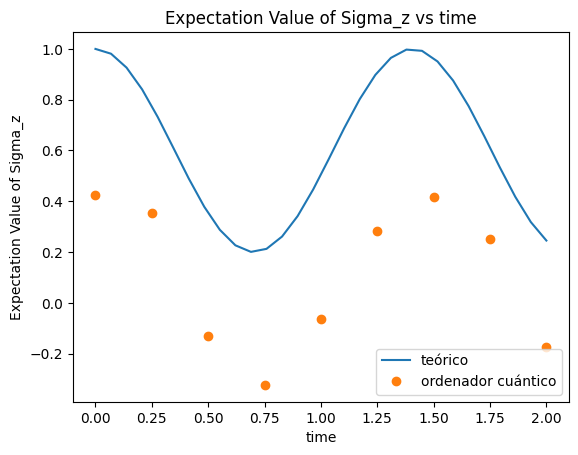

In [ ]:
# t= 0
mean_sigz_med_qyoto= np.zeros(9)
# Example: Use a quasi_dist array representing the measurement outcomes
#"quasi_dists":
[
	{
		"1000": 0.2650078294968683,
		"1001": -0.050768183900813245,
		"1010": -0.031418471460772486,
		"1011": 0.07542609086236819,
		"1100": 0.19353035920534623,
		"1101": -0.015488710541032666,
		"1110": -0.02451403241912712,
		"1111": 0.04891422816398132,
		"0000": 0.4022431114901538,
		"0001": -0.13079318249830643,
		"0010": -0.049118147417573324,
		"0011": 0.10984162260360056,
		"0100": 0.1875878403088532,
		"0101": -0.03080736393622027,
		"0110": -0.04293907486383232,
		"0111": 0.09329608490650616
	}
]

mean_sigz=((0.2650078294968683)+(-0.13079318249830643)+(-0.049118147417573324) + (0.1875878403088532))*2+\
 ((0.07542609086236819)+(-0.015488710541032666)+(-0.02451403241912712)+(0.09329608490650616))*(-2) +( 0.4022431114901538)*4 + (0.04891422816398132)*-4

mean_sigz_med= 0.25*mean_sigz
mean_sigz_med_qyoto[0]=mean_sigz_med
print("Observable Mean:", mean_sigz_med)

#t= 0.25
# Example: Use a quasi_dist array representing the measurement outcomes
#"quasi_dists":
[
	{
		"1000": 0.2292098788391147,
		"1001": -0.03907784991897571,
		"1010": -0.05370334173277631,
		"1011": 0.11122049910579569,
		"1100": 0.08356594788522179,
		"1101": -0.007455019056843948,
		"1110": 0.011716288848918885,
		"1111": 0.057775274629254435,
		"0000": 0.42552162816335753,
		"0001": -0.12557025343692796,
		"0010": -0.07592754109545932,
		"0011": 0.180799967020406,
		"0100": 0.12776745570525896,
		"0101": 0.024836817585941723,
		"0110": -0.015016138756424387,
		"0111": 0.06433638621413781
	}
]

mean_sigz=((0.2292098788391147)+(-0.12557025343692796)+(-0.07592754109545932) + (0.12776745570525896))*2+\
 ((0.11122049910579569)+( -0.007455019056843948)+(0.011716288848918885)+(0.06433638621413781))*(-2) +( 0.42552162816335753)*4 + (0.057775274629254435)*-4

mean_sigz_med= 0.25*mean_sigz
mean_sigz_med_qyoto[1]=mean_sigz_med
print("Observable Mean:", mean_sigz_med)


# t= 0.5

# Example: Use a quasi_dist array representing the measurement outcomes
#"quasi_dists":
[
    {
      "1000": 0.21570164652751814,
      "1001": -0.1114802047140634,
      "1010": -0.0895889656192231,
      "1011": 0.29718982937276184,
      "1100": 0.10444473052232793,
      "1101": 0.004450166295670898,
      "1110": -0.028485270219645933,
      "1111": 0.15088239720421467,
      "0000": 0.1405068643565574,
      "0001": -0.062444149337518,
      "0010": -0.1086822149207607,
      "0011": 0.3402370433003588,
      "0100": 0.08143633863748223,
      "0101": -0.018082763641101982,
      "0110": -0.01246268864930362,
      "0111": 0.09637724088472485
    }
  ]
mean_sigz=((0.21570164652751814)+(-0.062444149337518)+(-0.1086822149207607) + (0.08143633863748223))*2+\
 ((0.29718982937276184)+(0.004450166295670898)+(-0.028485270219645933)+(0.09637724088472485))*(-2) +(0.1405068643565574)*4 + (0.15088239720421467)*-4

mean_sigz_med= 0.25*mean_sigz
mean_sigz_med_qyoto[2]=mean_sigz_med
print("Observable Mean:", mean_sigz_med)



# t= 0.75

# Example: Use a quasi_dist array representing the measurement outcomes

[
    {
      "1000": 0.05696849387058076,
      "1001": -0.050404869670024256,
      "1010": -0.05950084999416002,
      "1011": 0.35025435630970664,
      "1100": 0.019197070120675935,
      "1101": -0.012153651000934032,
      "1110": -0.0033580470186678184,
      "1111": 0.17016477057171922,
      "0000": 0.1171165358489084,
      "0001": -0.06040278469410795,
      "0010": -0.1328698734258734,
      "0011": 0.4463364032566594,
      "0100": 0.06571419077052044,
      "0101": -0.004356677704552389,
      "0110": -0.03797412163897688,
      "0111": 0.13526905439852588
    }
  ]
mean_sigz=(( 0.05696849387058076)+(-0.06040278469410795)+(-0.1328698734258734) + ( 0.06571419077052044))*2+\
 ((0.35025435630970664)+(-0.012153651000934032)+(-0.0033580470186678184)+(0.13526905439852588))*(-2) +(0.1171165358489084)*4 + (0.17016477057171922)*-4

mean_sigz_med= 0.25*mean_sigz
mean_sigz_med_qyoto[3]=mean_sigz_med
print("Observable Mean:", mean_sigz_med)

# t= 1
# Example: Use a quasi_dist array representing the measurement outcomes
 #"quasi_dists":
[
    {
      "1000": 0.08914399163727375,
      "1001": -0.004934592899013454,
      "1010": -0.0374476456341406,
      "1011": 0.26771977055650015,
      "1100": 0.09979390702476225,
      "1101": -0.024875840114211827,
      "1110": -0.01955266107572677,
      "1111": 0.14513034910552142,
      "0000": 0.2545690537921002,
      "0001": -0.1024350500546268,
      "0010": -0.08112397526973379,
      "0011": 0.2551557314688462,
      "0100": 0.06621431833150454,
      "0101": 0.001371249489377271,
      "0110": -0.004056480996802052,
      "0111": 0.0953278746383695
    }
  ]

mean_sigz=((0.08914399163727375)+(-0.1024350500546268)+(-0.08112397526973379) + (0.06621431833150454))*2+\
 ((0.26771977055650015)+(-0.024875840114211827)+(-0.01955266107572677)+(0.0953278746383695))*(-2) +(0.2545690537921002)*4 + (0.14513034910552142)*-4

mean_sigz_med= 0.25*mean_sigz
mean_sigz_med_qyoto[4]=mean_sigz_med
print("Observable Mean:", mean_sigz_med)

# t= 1.25

# Example: Use a quasi_dist array representing the measurement outcomes
# "quasi_dists":
[
    {
      "1000": 0.24010330628469204,
      "1001": -0.05559938711561305,
      "1010": -0.06336148814416749,
      "1011": 0.13044855305580336,
      "1100": 0.14449647839511007,
      "1101": -0.008601797260724499,
      "1110": -0.011260988625364187,
      "1111": 0.035068960600693325,
      "0000": 0.3554240701103442,
      "0001": -0.04628289475194874,
      "0010": -0.03684121694064356,
      "0011": 0.10508147692617147,
      "0100": 0.1551713844956127,
      "0101": -0.01730957153417081,
      "0110": -0.007307199373840623,
      "0111": 0.08077031387804569
    }
  ]

mean_sigz=((0.24010330628469204)+(-0.04628289475194874)+(-0.03684121694064356) + (-0.03684121694064356))*2+\
 ((0.13044855305580336)+(-0.008601797260724499)+(-0.011260988625364187)+(0.08077031387804569))*(-2) +(0.3554240701103442)*4 + (0.035068960600693325)*-4

mean_sigz_med= 0.25*mean_sigz
mean_sigz_med_qyoto[5]=mean_sigz_med
print("Observable Mean:", mean_sigz_med)
# t= 1.5

# Example: Use a quasi_dist array representing the measurement outcomes
 #"quasi_dists":
[
	{
		"1000": 0.2952252175523708,
		"1001": -0.052899102987364874,
		"1010": -0.039362469282540724,
		"1011": 0.05789688723617842,
		"1100": 0.1446991024103144,
		"1101": -0.033533094626882254,
		"1110": -0.046170433007744795,
		"1111": 0.09540666133889054,
		"0000": 0.39676811411842505,
		"0001": -0.0787019378151638,
		"0010": -0.10641974781470277,
		"0011": 0.16993201210020312,
		"0100": 0.13790560937675014,
		"0101": 0.009111739712257129,
		"0110": 0.010375345260006974,
		"0111": 0.039766096429002556
	}
]

mean_sigz=((0.2952252175523708)+(-0.0787019378151638)+(-0.10641974781470277) + ( 0.13790560937675014))*2+\
 ((0.05789688723617842)+(-0.033533094626882254)+(-0.046170433007744795)+( 0.039766096429002556))*(-2) +(0.39676811411842505)*4 + (0.09540666133889054)*-4

mean_sigz_med= 0.25*mean_sigz
mean_sigz_med_qyoto[6]=mean_sigz_med
print("Observable Mean:", mean_sigz_med)


# t= 1.75

# Example: Use a quasi_dist array representing the measurement outcomes
[
    {
      "1000": 0.2199378264393174,
      "1001": -0.02569756668474913,
      "1010": -0.055171104228621586,
      "1011": 0.12653528485348467,
      "1100": 0.10650805386284909,
      "1101": -0.02281889075215008,
      "1110": -0.04818502718505463,
      "1111": 0.08898253780328944,
      "0000": 0.35386561287109364,
      "0001": -0.09842803104243474,
      "0010": -0.11014726200975289,
      "0011": 0.3227057634458279,
      "0100": 0.0924272005424551,
      "0101": -0.006318353058407757,
      "0110": -0.02050265375196017,
      "0111": 0.0763066088948137
    }
  ]

mean_sigz=((0.2199378264393174)+(-0.09842803104243474)+(-0.11014726200975289) + (0.0924272005424551))*2+\
 ((0.12653528485348467)+(-0.02281889075215008)+(-0.04818502718505463)+(0.0763066088948137))*(-2) +(0.35386561287109364)*4 + (0.08898253780328944)*-4

mean_sigz_med= 0.25*mean_sigz
mean_sigz_med_qyoto[7]=mean_sigz_med
print("Observable Mean:", mean_sigz_med)

# t= 2

# Example: Use a quasi_dist array representing the measurement outcomes
[
    {
      "1000": 0.10534105165918277,
      "1001": -0.06379735575676539,
      "1010": -0.06942153439107547,
      "1011": 0.30317756838231597,
      "1100": 0.03730869281460948,
      "1101": -0.005368436463120518,
      "1110": -0.033598568497387286,
      "1111": 0.13280846412385497,
      "0000": 0.1386893118753576,
      "0001": -0.04276568214291449,
      "0010": -0.09392502144600799,
      "0011": 0.45804700971274653,
      "0100": 0.017614307658797023,
      "0101": 0.029832433937737674,
      "0110": 0.002693069429484575,
      "0111": 0.08336468910318441
    }
  ]

mean_sigz=((0.10534105165918277)+(-0.04276568214291449)+(-0.09392502144600799) + (0.017614307658797023))*2+\
 ((0.30317756838231597)+(-0.005368436463120518)+(-0.033598568497387286)+(0.08336468910318441))*(-2) +(0.1386893118753576)*4 + (0.13280846412385497)*-4

mean_sigz_med= 0.25*mean_sigz
mean_sigz_med_qyoto[8]=mean_sigz_med
print("Observable Mean:", mean_sigz_med)

t_values2 = np.linspace(0,2,9)
I0 = plt.plot(t_values, expVals[:,0])
#I1 = plt.plot(t_values, expValsx[:,1])
#I2 = plt.plot(t_values, expVals[:,2])
#plt.legend( (I0[0], I1[0], I2[0]), ("lamb = 0.5", "lamb = 0.9","lamb = 1.8"))

#plt.ylim([0,1])
plt.title('Expectation Value of Sigma_z vs t')
I1 = plt.plot(t_values2,mean_sigz_med_qyoto,'o')
#plt.ylim([0,1.3])
plt.xlabel('time')
plt.ylabel('Expectation Value of Sigma_z')
plt.title('Expectation Value of Sigma_z vs time')
plt.legend( (I0[0],I1[0]), ("teórico","ordenador cuántico"))
plt.show()

In [ ]:
pip install qiskit-ibmq-provider

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 241.5/241.5 kB 7.5 MB/s eta 0:00:00
  Attempting uninstall: requests-ntlm
    Found existing installation: requests-ntlm 1.2.0
    Uninstalling requests-ntlm-1.2.0:
      Successfully uninstalled requests-ntlm-1.2.0


In [ ]:
#Noise model


# Import from Qiskit Aer noise module
from qiskit_aer.noise import (
    NoiseModel,
    QuantumError,
    ReadoutError,
    depolarizing_error,
    pauli_error,
    thermal_relaxation_error,
)

# Define the qubits in your circuit
num_qubits = 4

# Error rates
ecr_error_rate = 8.2e-3         # original 8.2e-3
sx_error_rate = 2.483e-4         # original 2.483e-4
readout_error_rate = 1.51e-2      # original 1.51e-2

# T1 and T2 values
t1_values = [221.83e-6] * num_qubits  # T1 times in seconds
t2_values = [114.35e-6] * num_qubits  # T2 times in seconds

# Create depolarizing errors for ECR and SX gates
ecr_error = depolarizing_error(ecr_error_rate, 2)  # Two-qubit error
sx_error = depolarizing_error(sx_error_rate, 1)

# Create thermal relaxation error for T1 and T2 times
t1_errors = [thermal_relaxation_error(t1, t2, 0) for t1, t2 in zip(t1_values, t2_values)]
t2_errors = [thermal_relaxation_error(t1, t2, 0) for t1, t2 in zip(t1_values, t2_values)]

# Create a noise model
noise_model = NoiseModel()
noise_model_kyoto=NoiseModel()

# Add errors to the noise model

# probabilitiesv = np.zeros([4,2**4])+readout_error_rate

probabilities =np.zeros([16,16])
p1=0.4
p2=(1-p1)/15
for i in range(16):
  for j in range(16):
    if i==j:
      probabilities[i,j]=p1
    else:
      probabilities[i,j]=p2

probabilities=probabilities.tolist()
print(probabilities)
readout_error= probabilities

# intento bit flip

matrix = np.zeros([16,16])

matrix[0,:]=[1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0]
probm=0.6
num=1
for i in range(15):
  matrix[i+1,i+1]=probm
  for j in range(15):
    if j<(i+1):
      matrix[i+1,j]= (1-probm)/(num)

  num +=1

print(matrix)


matrix=(matrix).tolist()

#noise_model.add_all_qubit_quantum_error(QuantumError(matrix),qubits=[0,1,2,3])
#noise_model.add_readout_error(ReadoutError(matrix),qubits=[0,1,2,3])


# intento bit flip error


p1f=0.5 #probabilidad de bit flip from 1 to 0
p2f=0.005 #probabilidad de bit flip from 0 to 1

for qubit in range(num_qubits - 1):  # For CNOT gate, go up to the second-to-last qubit
    # Add ECR error to the CNOT gate on each qubit pair
    noise_model.add_quantum_error(ecr_error, 'ecr', [qubit, qubit + 1])
    noise_model_kyoto.add_quantum_error(ecr_error, 'ecr', [qubit, qubit + 1])

    # Add SX error to the single-qubit gates
    noise_model.add_quantum_error(sx_error, 'sx', [qubit])
    noise_model_kyoto.add_quantum_error(ecr_error, 'ecr', [qubit, qubit + 1])

    # Add readout error to the measurement gates
    # Add readout error to the measurement gates
    #readout_error= probabilities

      # Assuming qubits are labeled 0 to 3

    # Add T1 and T2 errors to the single-qubit gates (thermal relaxation)
    noise_model.add_quantum_error(t1_errors[qubit], 'id', [qubit])
    noise_model.add_quantum_error(t2_errors[qubit], 'id', [qubit])
    noise_model_kyoto.add_quantum_error(ecr_error, 'ecr', [qubit, qubit + 1])
    noise_model_kyoto.add_quantum_error(ecr_error, 'ecr', [qubit, qubit + 1])

    # Create custom errors based on the initial state
    # error_0 = QuantumError(depolarizing_error(p1f, 1))
    # error_1 = QuantumError(depolarizing_error(p2f, 1))

    # Add errors to the noise model based on the initial state of each qubit
    # noise_model.add_quantum_error(error_0, 'x', [qubit], warnings=False)
    # noise_model.add_quantum_error(error_1, 'x', [qubit], warnings=False)
    # noise_model_kyoto.add_quantum_error(error_0, 'x', [qubit], warnings=False)
    # noise_model_kyoto.add_quantum_error(error_1, 'x', [qubit], warnings=False)

# Handle the last qubit separately for the single-qubit errors
qubit = num_qubits - 1
noise_model.add_quantum_error(sx_error, 'sx', [qubit])
#noise_model.add_readout_error([readout_error_rate, 1 - readout_error_rate], [qubit])
noise_model.add_quantum_error(t1_errors[qubit], 'id', [qubit])
noise_model.add_quantum_error(t2_errors[qubit], 'id', [qubit])
noise_model_kyoto.add_quantum_error(t1_errors[qubit], 'id', [qubit])
noise_model_kyoto.add_quantum_error(t2_errors[qubit], 'id', [qubit])


# Print the noise model
print(noise_model)




[[0.4, 0.04, 0.04, 0.04, 0.04, 0.04, 0.04, 0.04, 0.04, 0.04, 0.04, 0.04, 0.04, 0.04, 0.04, 0.04], [0.04, 0.4, 0.04, 0.04, 0.04, 0.04, 0.04, 0.04, 0.04, 0.04, 0.04, 0.04, 0.04, 0.04, 0.04, 0.04], [0.04, 0.04, 0.4, 0.04, 0.04, 0.04, 0.04, 0.04, 0.04, 0.04, 0.04, 0.04, 0.04, 0.04, 0.04, 0.04], [0.04, 0.04, 0.04, 0.4, 0.04, 0.04, 0.04, 0.04, 0.04, 0.04, 0.04, 0.04, 0.04, 0.04, 0.04, 0.04], [0.04, 0.04, 0.04, 0.04, 0.4, 0.04, 0.04, 0.04, 0.04, 0.04, 0.04, 0.04, 0.04, 0.04, 0.04, 0.04], [0.04, 0.04, 0.04, 0.04, 0.04, 0.4, 0.04, 0.04, 0.04, 0.04, 0.04, 0.04, 0.04, 0.04, 0.04, 0.04], [0.04, 0.04, 0.04, 0.04, 0.04, 0.04, 0.4, 0.04, 0.04, 0.04, 0.04, 0.04, 0.04, 0.04, 0.04, 0.04], [0.04, 0.04, 0.04, 0.04, 0.04, 0.04, 0.04, 0.4, 0.04, 0.04, 0.04, 0.04, 0.04, 0.04, 0.04, 0.04], [0.04, 0.04, 0.04, 0.04, 0.04, 0.04, 0.04, 0.04, 0.4, 0.04, 0.04, 0.04, 0.04, 0.04, 0.04, 0.04], [0.04, 0.04, 0.04, 0.04, 0.04, 0.04, 0.04, 0.04, 0.04, 0.4, 0.04, 0.04, 0.04, 0.04, 0.04, 0.04], [0.04, 0.04, 0.04, 0.04, 0.04

NoiseModel:
  Basis gates: ['cx', 'ecr', 'id', 'rz', 'sx']
  Instructions with noise: ['ecr', 'sx']
  Qubits with noise: [0, 1, 2, 3]
  Specific qubit errors: [('ecr', (0, 1)), ('ecr', (1, 2)), ('ecr', (2, 3)), ('sx', (0,)), ('sx', (1,)), ('sx', (2,)), ('sx', (3,))]


In [ ]:
# IBM simulation proccedure
from qiskit import IBMQ
IBMQ.save_account('be88cbe2fe8c391830511ed2a4a384d2a8bb7cbc8c7defcb79e4302fb287533994cbbf300d1a4ee3996a616cf818c157b58659e9023456e4d190bdb355b84130')
from qiskit import IBMQ
provider = IBMQ.load_account()
backendkyot = provider.get_backend('ibm_kyoto')
noise_model_kyoto=NoiseModel.from_backend(backendkyot)


<ipython-input-11-1d3f2977bc60>:3: DeprecationWarning: The package qiskit.providers.ibmq is being deprecated. Please see https://ibm.biz/provider_migration_guide to get instructions on how to migrate to qiskit-ibm-provider (https://github.com/Qiskit/qiskit-ibm-provider) and qiskit-ibm-runtime (https://github.com/Qiskit/qiskit-ibm-runtime).
  IBMQ.save_account('be88cbe2fe8c391830511ed2a4a384d2a8bb7cbc8c7defcb79e4302fb287533994cbbf300d1a4ee3996a616cf818c157b58659e9023456e4d190bdb355b84130')
<ipython-input-11-1d3f2977bc60>:3: DeprecationWarning: The qiskit.IBMQ entrypoint and the qiskit-ibmq-provider package (accessible from 'qiskit.providers.ibmq`) are deprecated and will be removed in a future release. Instead you should use the qiskit-ibm-provider package which is accessible from 'qiskit_ibm_provider'. You can install it with 'pip install qiskit_ibm_provider'. Just replace 'qiskit.IBMQ' with 'qiskit_ibm_provider.IBMProvider'
  IBMQ.save_account('be88cbe2fe8c391830511ed2a4a384d2a8bb7cbc

resultados exp ibm

In [ ]:
# lo de arriba pasado a limpio, 1024 shots

#from qiskit import QuantumCircuit, Aer, transpile, assemble
from qiskit import *
import numpy as np

from qiskit.primitives import Estimator

estimator = Estimator()

from qiskit.quantum_info import SparsePauliOp

observable=SparsePauliOp(['IZII', 'ZIII', 'IIIZ','IIZI'], coeffs=[0.25 +0.j,  0.25+0.j,  0.25 +0.j,  0.25 +0.j])

from qiskit_aer import AerSimulator

from qiskit.opflow import CircuitOp, CircuitStateFn, X, Y, Z, I

# Define a range of lambda values
lambda_values = np.linspace(0, 1.75, 20)

# Simulate the circuit for each lambda value

sigmaz_exact = []
sigmaz_nonoise=[]
sigmaz_noise=[]
sigmaz_noise_exact=[]
sigmaz_noise_kyoto=[]

numb=50   # tiene q ser par, para modelizar el error de
pd=0.1   # probabilidad de decay
pdf=0.00 # probabilidad de decay al estado fundamental del sistema
for lambda_val in lambda_values:
  if lambda_val >=1:
    qc = create_circuit(lambda_val)
    qcn = create_circuit(lambda_val,'True')

    # Use Aer for exact simulator
    simulator = Aer.get_backend('qasm_simulator')
    transpiled_circuit = transpile(qcn, simulator)
    result = simulator.run(assemble(transpiled_circuit)).result()
    counts = result.get_counts(qcn)
    # Define the eigenvalues for sigma_Z
    N_0000 = counts.get('0000', 0)
    N_0001 = counts.get('0001', 0)
    N_0010 = counts.get('0010', 0)
    N_0100 = counts.get('0100', 0)
    N_1000 = counts.get('1000', 0)
    N_1110= counts.get('1110', 0)
    N_1011= counts.get('1011', 0)
    N_1101= counts.get('1101', 0)
    N_0111= counts.get('0111', 0)
# ... Repeat for all possible outcomes

# Calculate the expectation value
    mean_sigma_Z_nonoise = (N_0000 + (N_0001 +N_0010 +N_0100 +N_1000)*0.5 - (N_0111+N_1110+N_1011+ N_1101)*0.5) / sum(counts.values())


    # Calculate the mean of sigma_Z
    #mean_sigma_Z_nonoise = sum(counts[outcome] * eigenvalues[outcome[-1]] for outcome in counts) / sum(counts.values())
    sigmaz_nonoise.append(mean_sigma_Z_nonoise)
    #print("Mean of sigma_Z with counts:",lambda_val,'=>', mean_sigma_Z_nonoise)

        # Calculate and store the exact expectation value

    job =estimator.run(qc,observable)
    print(job.time_per_step())
    #print("Mean of sigma_Z exact:",job.result().values[0])
    expectation_value=job.result().values[0]
    sigmaz_exact.append(expectation_value)

    # Toy-model of errors model

    sim_noise = AerSimulator(noise_model=noise_model) # noise_model = noise_model si quieres usar el toy-model
    #sim_noise=Aer.get_backend(noise_model=noise_model)
    transpiled_circuitnoise = transpile(qcn, sim_noise)
    resultnoise = sim_noise.run(assemble(transpiled_circuitnoise),observable).result()
    counts = resultnoise.get_counts(qcn)
    N_0000 = counts.get('0000', 0)
    N_0001 = counts.get('0001', 0)
    N_0010 = counts.get('0010', 0)
    N_0100 = counts.get('0100', 0)
    N_1000 = counts.get('1000', 0)
    N_1110= counts.get('1110', 0)
    N_1011= counts.get('1011', 0)
    N_1101= counts.get('1101', 0)
    N_0111= counts.get('0111', 0)
    N_0011=counts.get('0011', 0)
    N_0101=counts.get('0101', 0)
    N_0110=counts.get('0110', 0)
    N_1100=counts.get('1100', 0)
    N_1010=counts.get('1010', 0)
    N_1001=counts.get('1001', 0)
    N_1111=counts.get('1111', 0)

# ... Repeat for all possible outcomes

# Calculate the expectation value


# Calculate the expectation value
    numb=N_1111
    numb1=(N_0111+N_1110+N_1011+ N_1101)
    numb2=(N_0011+N_0101+N_0110+N_1100+N_1100+N_1010+N_1001)
    numb3=(N_0001 +N_0010 +N_0100 +N_1000)
    numb4=N_0000
    #mean_sigma_Z_noise = (N_0000+pdf*(numb+numb1+numb2+numb3)+numb*pd*pd*pd*pd+numb1*pd*pd*pd+numb2*pd*pd+numb3*pd + (N_0001 +N_0010 +N_0100 +N_1000+numb*pd*pd*pd+numb1*pd*pd+numb2*pd-numb3*(pd+pdf))*0.5+(N_0011+N_0101+N_0110+N_1100+N_1100+N_1010+N_1001+numb*pd*pd+numb1*pd-numb2*(pd+pdf))*0 - (N_0111+N_1110+N_1011+ N_1101+numb*pd-numb1*(pd+pdf))*0.5-(N_1111-numb*(pd+pdf))) / sum(counts.values())
    mean_sigma_Z_noise = (-(numb-numb*pd)-0.5*(numb1*(1-pd)+numb*pd*0.25)+0*(numb2*(1-pd)+numb*pd*0.25+numb1*pd*(1/3))+0.5*(numb3*(1-pd)+numb*pd*0.25+numb1*pd*(1/3)+numb2*pd*0)+(numb4+numb*pd*0.25+numb1*pd*(1/3)+numb2*pd*1+numb3*pd) )/ sum(counts.values())

    # N3p= (N_1111-numb*(pd+pdf))
    # N2p=(N_0111+N_1110+N_1011+ N_1101+numb*pd-numb1*(pd+pdf))
    # N1p=(N_0001 +N_0010 +N_0100 +N_1000+numb*pd*pd*pd+numb1*pd*pd+numb2*pd-numb3*(pd+pdf))
    # N0p=(N_0000+pdf*(numb+numb1+numb2+numb3)+numb*pd*pd*pd*pd+numb1*pd*pd*pd+numb2*pd*pd+numb3*pd)

    #mean_sigma_Z_noise = (N_0000+pdf*(numb+numb1+numb2+numb3)+numb*pd*pd*pd*pd+numb1*pd*pd*pd+numb2*pd*pd+numb3*pd + (N_0001 +N_0010 +N_0100 +N_1000+numb*pd*pd*pd+numb1*pd*pd+numb2*pd-numb3*(pd+pdf))*0.5+(N_0011+N_0101+N_0110+N_1100+N_1100+N_1010+N_1001+numb*pd*pd+numb1*pd-numb2*(pd+pdf))*0 - (N_0111+N_1110+N_1011+ N_1101+numb*pd-numb1*(pd+pdf))*0.5-(N_1111-numb*(pd+pdf))) / sum(counts.values())
    print('N_0111+N_1110+N_1011+ N_1101=',N_0111+N_1110+N_1011+ N_1101,'and N_0011+N_0101+N_0110+N_1100+N_1100+N_1010',N_0011+N_0101+N_0110+N_1100+N_1100+N_1010, ' and N_0001 +N_0010 +N_0100 +N_1000=',N_0001 +N_0010 +N_0100 +N_1000)
    #print("Mean of sigma_Z with noise with counts:", mean_sigma_Z_noise)
    sigmaz_noise.append(mean_sigma_Z_noise)

        # Toy-model of errors from noise model from kyoto

    sim_noise_ky = AerSimulator(noise_model=noise_model_kyoto) # noise_model = noise_model si quieres usar el toy-model
    #sim_noise=Aer.get_backend(noise_model=noise_model)
    transpiled_circuitnoiseky = transpile(qcn, sim_noise_ky)
    resultnoise = sim_noise.run(assemble(transpiled_circuitnoiseky),observable).result()
    counts = resultnoise.get_counts(qcn)
    N_0000 = counts.get('0000', 0)
    N_0001 = counts.get('0001', 0)
    N_0010 = counts.get('0010', 0)
    N_0100 = counts.get('0100', 0)
    N_1000 = counts.get('1000', 0)
    N_1110= counts.get('1110', 0)
    N_1011= counts.get('1011', 0)
    N_1101= counts.get('1101', 0)
    N_0111= counts.get('0111', 0)
    # ... Repeat for all possible outcomes

       # tiene q ser par

# Calculate the expectation value
    mean_sigma_Z_kyoto = (N_0000 + (N_0001 +N_0010 +N_0100 +N_1000)*0.5 - (N_0111+N_1110+N_1011+ N_1101)*0.5) / sum(counts.values())

    #print("Mean of sigma_Z with noise with counts:", mean_sigma_Z_noise)
    sigmaz_noise_kyoto.append(mean_sigma_Z_kyoto)



  if lambda_val <1:
    qc2 = create_circuit2(lambda_val)
    qc2n=create_circuit2(lambda_val,'True')

    # Use Aer simulator
    simulator = Aer.get_backend('qasm_simulator')
    transpiled_circuit = transpile(qc2n, simulator)
    result = simulator.run(assemble(transpiled_circuit)).result()
    counts = result.get_counts(qc2n)
    N_0000 = counts.get('0000', 0)
    N_0001 = counts.get('0001', 0)
    N_0010 = counts.get('0010', 0)
    N_0100 = counts.get('0100', 0)
    N_1000 = counts.get('1000', 0)
    N_1110= counts.get('1110', 0)
    N_1011= counts.get('1011', 0)
    N_1101= counts.get('1101', 0)
    N_0111= counts.get('0111', 0)
# ... Repeat for all possible outcomes

# Calculate the expectation value
    mean_sigma_Z_nonoise = (N_0000 + (N_0001 +N_0010 +N_0100 +N_1000)*0.5 - (N_0111+N_1110+N_1011+ N_1101)*0.5) / sum(counts.values())
    #print("Mean of sigma_Z with counts:",lambda_val,'=>', mean_sigma_Z_nonoise)
    sigmaz_nonoise.append(mean_sigma_Z_nonoise)

    # Calculate and store the expectation value

    job =estimator.run(qc2, observable)
    expectation_value=job.result().values[0]
    sigmaz_exact.append(expectation_value)
    #print("Mean of sigma_Z exactly:",lambda_val,'=>', expectation_value)

       ## Toy-model of errors model

    sim_noise = AerSimulator(noise_model=noise_model)                ## noise_model_kyoto for error model of kyoto
    transpiled_circuitnoise = transpile(qc2n, sim_noise)
    resultnoise = sim_noise.run(assemble(transpiled_circuitnoise),observable).result()
    counts = resultnoise.get_counts(qc2n)
    N_0000 = counts.get('0000', 0)
    N_0001 = counts.get('0001', 0)
    N_0010 = counts.get('0010', 0)
    N_0100 = counts.get('0100', 0)
    N_1000 = counts.get('1000', 0)
    N_1110= counts.get('1110', 0)
    N_1011= counts.get('1011', 0)
    N_1101= counts.get('1101', 0)
    N_0111= counts.get('0111', 0)
    N_0011=counts.get('0011', 0)
    N_0101=counts.get('0101', 0)
    N_0110=counts.get('0110', 0)
    N_1100=counts.get('1100', 0)
    N_1010=counts.get('1010', 0)
    N_1001=counts.get('1001', 0)
    N_1111=counts.get('1111', 0)

# ... Repeat for all possible outcomes

# Calculate the expectation value


# Calculate the expectation value
# Calculate the expectation value
    numb=N_1111
    numb1=(N_0111+N_1110+N_1011+ N_1101)
    numb2=(N_0011+N_0101+N_0110+N_1100+N_1100+N_1010+N_1001)
    numb3=(N_0001 +N_0010 +N_0100 +N_1000)
    numb4=N_0000
    #mean_sigma_Z_noise = (N_0000+pdf*(numb+numb1+numb2+numb3)+numb*pd*pd*pd*pd+numb1*pd*pd*pd+numb2*pd*pd+numb3*pd + (N_0001 +N_0010 +N_0100 +N_1000+numb*pd*pd*pd+numb1*pd*pd+numb2*pd-numb3*(pd+pdf))*0.5+(N_0011+N_0101+N_0110+N_1100+N_1100+N_1010+N_1001+numb*pd*pd+numb1*pd-numb2*(pd+pdf))*0 - (N_0111+N_1110+N_1011+ N_1101+numb*pd-numb1*(pd+pdf))*0.5-(N_1111-numb*(pd+pdf))) / sum(counts.values())
    mean_sigma_Z_noise = (-(numb-numb*pd)-0.5*(numb1*(1-pd)+numb*pd*0.25)+0*(numb2*(1-pd)+numb*pd*0.25+numb1*pd*(1/3))+0.5*(numb3*(1-pd)+numb*pd*0.25+numb2*pd*(1/2)+numb1*pd*(1/3))+(numb4+numb*pd*0.25+numb1*pd*(1/3)+numb2*pd*(1/2)+numb3*pd) )/ sum(counts.values())
    print('N_0111+N_1110+N_1011+ N_1101=',N_0111+N_1110+N_1011+ N_1101,'and N_0011+N_0101+N_0110+N_1100+N_1100+N_1010',N_0011+N_0101+N_0110+N_1100+N_1100+N_1010, ' and N_0001 +N_0010 +N_0100 +N_1000=',N_0001 +N_0010 +N_0100 +N_1000)
   #print(N_0111+N_1110+N_1011+ N_1101)

    sigmaz_noise.append(mean_sigma_Z_noise)

      ## Toy-model of errors from noise model from kyoto

    sim_noiseky = AerSimulator(noise_model=noise_model_kyoto) # noise_model = noise_model si quieres usar el toy-model
    #sim_noise=Aer.get_backend(noise_model=noise_model)
    transpiled_circuitnoiseky = transpile(qc2n, sim_noiseky)
    resultnoiseky = sim_noiseky.run(assemble(transpiled_circuitnoiseky),observable).result()
    counts = resultnoiseky.get_counts(qc2n)
    N_0000 = counts.get('0000', 0)
    N_0001 = counts.get('0001', 0)
    N_0010 = counts.get('0010', 0)
    N_0100 = counts.get('0100', 0)
    N_1000 = counts.get('1000', 0)
    N_1110= counts.get('1110', 0)
    N_1011= counts.get('1011', 0)
    N_1101= counts.get('1101', 0)
    N_0111= counts.get('0111', 0)
    # ... Repeat for all possible outcomes

       # tiene q ser par

# Calculate the expectation value
    mean_sigma_Z_kyoto = (N_0000 + (N_0001 +N_0010 +N_0100 +N_1000)*0.5 - (N_0111+N_1110+N_1011+ N_1101)*0.5) / sum(counts.values())

    #print("Mean of sigma_Z with noise kyoto with counts:", mean_sigma_Z_kyoto)
    sigmaz_noise_kyoto.append(mean_sigma_Z_kyoto)

# Plot the results

sigmaz_nonoisearr=np.array(sigmaz_nonoise)
sigmaz_noisearr=np.array(sigmaz_noise)
sigmaz_exactarr=np.array(sigmaz_noise_exact)
sigmaz_noise_kyotoarr=np.array(sigmaz_noise_kyoto)

#plt.plot(lambda_values, sigmaz_nonoisearr,'k',label='qasm simulator')
plt.plot(lambda_values, sigmaz_noisearr,'r',label='kyoto noise model 2.0 simulator')
plt.plot(lambda_values,sigmaz_noise_kyotoarr,'k',label='kyoto noise model simulator')
plt.plot(lambda_values, sigmaz_exact,'b',label='exact')

lambda_values2=np.linspace(0,1.75,10)
plt.plot(lambda_values2, mean_sigz_med_qyoto_2048,'o',label='kyoto IBM Q.C.')

plt.legend()
#plt.title('Experiment of 2048 shots')

plt.ylim([0,1.2])
plt.xlabel(r'$\lambda$')
plt.ylabel(r'$\langle \sigma_z \rangle$')




<ipython-input-12-9ed194bf4eff>:17: DeprecationWarning: The ``qiskit.opflow`` module is deprecated as of qiskit-terra 0.24.0. It will be removed no earlier than 3 months after the release date. For code migration guidelines, visit https://qisk.it/opflow_migration.
  from qiskit.opflow import CircuitOp, CircuitStateFn, X, Y, Z, I
<ipython-input-12-9ed194bf4eff>:155: DeprecationWarning: Using a qobj for run() is deprecated as of qiskit-aer 0.9.0 and will be removed no sooner than 3 months from that release date. Transpiled circuits should now be passed directly using `backend.run(circuits, **run_options).
  result = simulator.run(assemble(transpiled_circuit)).result()
<ipython-input-12-9ed194bf4eff>:184: DeprecationWarning: Using a qobj for run() is deprecated as of qiskit-aer 0.9.0 and will be removed no sooner than 3 months from that release date. Transpiled circuits should now be passed directly using `backend.run(circuits, **run_options).
  resultnoise = sim_noise.run(assemble(transp

N_0111+N_1110+N_1011+ N_1101= 531 and N_0011+N_0101+N_0110+N_1100+N_1100+N_1010 1  and N_0001 +N_0010 +N_0100 +N_1000= 491
N_0111+N_1110+N_1011+ N_1101= 459 and N_0011+N_0101+N_0110+N_1100+N_1100+N_1010 2  and N_0001 +N_0010 +N_0100 +N_1000= 560
N_0111+N_1110+N_1011+ N_1101= 418 and N_0011+N_0101+N_0110+N_1100+N_1100+N_1010 0  and N_0001 +N_0010 +N_0100 +N_1000= 605
N_0111+N_1110+N_1011+ N_1101= 385 and N_0011+N_0101+N_0110+N_1100+N_1100+N_1010 1  and N_0001 +N_0010 +N_0100 +N_1000= 638
N_0111+N_1110+N_1011+ N_1101= 341 and N_0011+N_0101+N_0110+N_1100+N_1100+N_1010 0  and N_0001 +N_0010 +N_0100 +N_1000= 683
N_0111+N_1110+N_1011+ N_1101= 272 and N_0011+N_0101+N_0110+N_1100+N_1100+N_1010 3  and N_0001 +N_0010 +N_0100 +N_1000= 750
N_0111+N_1110+N_1011+ N_1101= 262 and N_0011+N_0101+N_0110+N_1100+N_1100+N_1010 1  and N_0001 +N_0010 +N_0100 +N_1000= 757
N_0111+N_1110+N_1011+ N_1101= 242 and N_0011+N_0101+N_0110+N_1100+N_1100+N_1010 0  and N_0001 +N_0010 +N_0100 +N_1000= 781
N_0111+N_1110+N_

<ipython-input-12-9ed194bf4eff>:41: DeprecationWarning: Using a qobj for run() is deprecated as of qiskit-aer 0.9.0 and will be removed no sooner than 3 months from that release date. Transpiled circuits should now be passed directly using `backend.run(circuits, **run_options).
  result = simulator.run(assemble(transpiled_circuit)).result()


AttributeError: 'PrimitiveJob' object has no attribute 'time_per_step'

<ipython-input-13-57512fd001b9>:163: DeprecationWarning: Using a qobj for run() is deprecated as of qiskit-aer 0.9.0 and will be removed no sooner than 3 months from that release date. Transpiled circuits should now be passed directly using `backend.run(circuits, **run_options).
  result = simulator.run(assemble(transpiled_circuit)).result()
<ipython-input-13-57512fd001b9>:192: DeprecationWarning: Using a qobj for run() is deprecated as of qiskit-aer 0.9.0 and will be removed no sooner than 3 months from that release date. Transpiled circuits should now be passed directly using `backend.run(circuits, **run_options).
  resultnoise = sim_noise.run(assemble(transpiled_circuitnoise),observable, shots=num_shots).result()
<ipython-input-13-57512fd001b9>:238: DeprecationWarning: Using a qobj for run() is deprecated as of qiskit-aer 0.9.0 and will be removed no sooner than 3 months from that release date. Transpiled circuits should now be passed directly using `backend.run(circuits, **run_opti

N_0111+N_1110+N_1011+ N_1101= 998 and N_0011+N_0101+N_0110+N_1100+N_1100+N_1010 1  and N_0001 +N_0010 +N_0100 +N_1000= 1047
N_0111+N_1110+N_1011+ N_1101= 945 and N_0011+N_0101+N_0110+N_1100+N_1100+N_1010 2  and N_0001 +N_0010 +N_0100 +N_1000= 1099
N_0111+N_1110+N_1011+ N_1101= 839 and N_0011+N_0101+N_0110+N_1100+N_1100+N_1010 1  and N_0001 +N_0010 +N_0100 +N_1000= 1208
N_0111+N_1110+N_1011+ N_1101= 751 and N_0011+N_0101+N_0110+N_1100+N_1100+N_1010 0  and N_0001 +N_0010 +N_0100 +N_1000= 1296
N_0111+N_1110+N_1011+ N_1101= 690 and N_0011+N_0101+N_0110+N_1100+N_1100+N_1010 4  and N_0001 +N_0010 +N_0100 +N_1000= 1353
N_0111+N_1110+N_1011+ N_1101= 613 and N_0011+N_0101+N_0110+N_1100+N_1100+N_1010 2  and N_0001 +N_0010 +N_0100 +N_1000= 1431
N_0111+N_1110+N_1011+ N_1101= 557 and N_0011+N_0101+N_0110+N_1100+N_1100+N_1010 5  and N_0001 +N_0010 +N_0100 +N_1000= 1487
N_0111+N_1110+N_1011+ N_1101= 464 and N_0011+N_0101+N_0110+N_1100+N_1100+N_1010 5  and N_0001 +N_0010 +N_0100 +N_1000= 1581
N_0111+N

<ipython-input-13-57512fd001b9>:47: DeprecationWarning: Using a qobj for run() is deprecated as of qiskit-aer 0.9.0 and will be removed no sooner than 3 months from that release date. Transpiled circuits should now be passed directly using `backend.run(circuits, **run_options).
  result = simulator.run(assemble(transpiled_circuit), shots=num_shots).result()
<ipython-input-13-57512fd001b9>:82: DeprecationWarning: Using a qobj for run() is deprecated as of qiskit-aer 0.9.0 and will be removed no sooner than 3 months from that release date. Transpiled circuits should now be passed directly using `backend.run(circuits, **run_options).
  resultnoise = sim_noise.run(assemble(transpiled_circuitnoise),observable, shots=num_shots).result()
<ipython-input-13-57512fd001b9>:133: DeprecationWarning: Using a qobj for run() is deprecated as of qiskit-aer 0.9.0 and will be removed no sooner than 3 months from that release date. Transpiled circuits should now be passed directly using `backend.run(circu

N_0111+N_1110+N_1011+ N_1101= 0 and N_0011+N_0101+N_0110+N_1100+N_1100+N_1010 289  and N_0001 +N_0010 +N_0100 +N_1000= 2
N_0111+N_1110+N_1011+ N_1101= 0 and N_0011+N_0101+N_0110+N_1100+N_1100+N_1010 264  and N_0001 +N_0010 +N_0100 +N_1000= 1
N_0111+N_1110+N_1011+ N_1101= 0 and N_0011+N_0101+N_0110+N_1100+N_1100+N_1010 236  and N_0001 +N_0010 +N_0100 +N_1000= 1
N_0111+N_1110+N_1011+ N_1101= 2 and N_0011+N_0101+N_0110+N_1100+N_1100+N_1010 195  and N_0001 +N_0010 +N_0100 +N_1000= 3
N_0111+N_1110+N_1011+ N_1101= 0 and N_0011+N_0101+N_0110+N_1100+N_1100+N_1010 197  and N_0001 +N_0010 +N_0100 +N_1000= 4
N_0111+N_1110+N_1011+ N_1101= 0 and N_0011+N_0101+N_0110+N_1100+N_1100+N_1010 208  and N_0001 +N_0010 +N_0100 +N_1000= 3
N_0111+N_1110+N_1011+ N_1101= 0 and N_0011+N_0101+N_0110+N_1100+N_1100+N_1010 153  and N_0001 +N_0010 +N_0100 +N_1000= 4
N_0111+N_1110+N_1011+ N_1101= 0 and N_0011+N_0101+N_0110+N_1100+N_1100+N_1010 153  and N_0001 +N_0010 +N_0100 +N_1000= 4
N_0111+N_1110+N_1011+ N_1101= 0 

Text(0, 0.5, '$\\langle \\sigma_z \\rangle$')

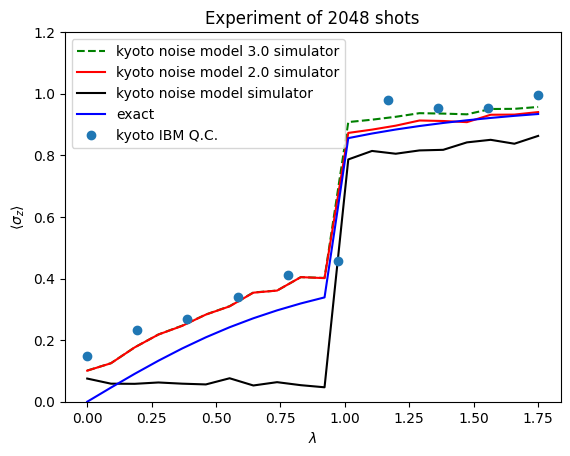

In [ ]:
# lo de arriba pasado a limpio, 2048 shots

num_shots=2048

#from qiskit import QuantumCircuit, Aer, transpile, assemble
from qiskit import *
import numpy as np

from qiskit.primitives import Estimator

estimator = Estimator()

from qiskit.quantum_info import SparsePauliOp

observable=SparsePauliOp(['IZII', 'ZIII', 'IIIZ','IIZI'], coeffs=[0.25 +0.j,  0.25+0.j,  0.25 +0.j,  0.25 +0.j])

from qiskit_aer import AerSimulator

from qiskit.opflow import CircuitOp, CircuitStateFn, X, Y, Z, I

# Define a range of lambda values
lambda_values = np.linspace(0, 1.75, 20)

# Simulate the circuit for each lambda value

sigmaz_exact = []
sigmaz_nonoise=[]
sigmaz_noise=[]
sigmaz_noise_exact=[]
sigmaz_noise_kyoto=[]
sigmaz_noise_model3=[]

#numb=50   # tiene q ser par, para modelizar el error de
pd=0.15  # probabilidad de decay
pdf=0.1*0 # probabilidad de decay al estado fundamental del sistema

ptr= 0.25

for lambda_val in lambda_values:
  if lambda_val >=1:
    qc = create_circuit(lambda_val)
    qcn = create_circuit(lambda_val,'True')

    # Use Aer for exact simulator
    simulator = Aer.get_backend('qasm_simulator')
    transpiled_circuit = transpile(qcn, simulator)
    result = simulator.run(assemble(transpiled_circuit), shots=num_shots).result()
    counts = result.get_counts(qcn)
    # Define the eigenvalues for sigma_Z
    N_0000 = counts.get('0000', 0)
    N_0001 = counts.get('0001', 0)
    N_0010 = counts.get('0010', 0)
    N_0100 = counts.get('0100', 0)
    N_1000 = counts.get('1000', 0)
    N_1110= counts.get('1110', 0)
    N_1011= counts.get('1011', 0)
    N_1101= counts.get('1101', 0)
    N_0111= counts.get('0111', 0)
# ... Repeat for all possible outcomes

# Calculate the expectation value
    mean_sigma_Z_nonoise = (N_0000 + (N_0001 +N_0010 +N_0100 +N_1000)*0.5 - (N_0111+N_1110+N_1011+ N_1101)*0.5) / sum(counts.values())


    # Calculate the mean of sigma_Z
    #mean_sigma_Z_nonoise = sum(counts[outcome] * eigenvalues[outcome[-1]] for outcome in counts) / sum(counts.values())
    sigmaz_nonoise.append(mean_sigma_Z_nonoise)
    #print("Mean of sigma_Z with counts:",lambda_val,'=>', mean_sigma_Z_nonoise)

        # Calculate and store the exact expectation value

    job =estimator.run(qc,observable)
    #print("Mean of sigma_Z exact:",job.result().values[0])
    expectation_value=job.result().values[0]
    sigmaz_exact.append(expectation_value)

    # Toy-model of errors model

    sim_noise = AerSimulator(noise_model=noise_model) # noise_model = noise_model si quieres usar el toy-model
    #sim_noise=Aer.get_backend(noise_model=noise_model)
    transpiled_circuitnoise = transpile(qcn, sim_noise)
    resultnoise = sim_noise.run(assemble(transpiled_circuitnoise),observable, shots=num_shots).result()
    counts = resultnoise.get_counts(qcn)
    N_0000 = counts.get('0000', 0)
    N_0001 = counts.get('0001', 0)
    N_0010 = counts.get('0010', 0)
    N_0100 = counts.get('0100', 0)
    N_1000 = counts.get('1000', 0)
    N_1110= counts.get('1110', 0)
    N_1011= counts.get('1011', 0)
    N_1101= counts.get('1101', 0)
    N_0111= counts.get('0111', 0)
    N_0011=counts.get('0011', 0)
    N_0101=counts.get('0101', 0)
    N_0110=counts.get('0110', 0)
    N_1100=counts.get('1100', 0)
    N_1010=counts.get('1010', 0)
    N_1001=counts.get('1001', 0)
    N_1111=counts.get('1111', 0)

# ... Repeat for all possible outcomes

# Calculate the expectation value


# Calculate the expectation value
    numb=N_1111
    numb1=(N_0111+N_1110+N_1011+ N_1101)
    numb2=(N_0011+N_0101+N_0110+N_1100+N_1100+N_1010+N_1001)
    numb3=(N_0001 +N_0010 +N_0100 +N_1000)
    numb4=N_0000
    mean_sigma_Z_noise = (N_0000+pdf*(numb+numb1+numb2+numb3)+numb*pd*pd*pd*pd+numb1*pd*pd*pd+numb2*pd*pd+numb3*pd + (N_0001 +N_0010 +N_0100 +N_1000+numb*pd*pd*pd+numb1*pd*pd+numb2*pd-numb3*(pd+pdf))*0.5+(N_0011+N_0101+N_0110+N_1100+N_1100+N_1010+N_1001+numb*pd*pd+numb1*pd-numb2*(pd+pd**2+pdf))*0 - (N_0111+N_1110+N_1011+ N_1101+numb*pd-numb1*(pd+pd**2+pd**3+pdf))*0.5-(N_1111-numb*(pd+pd**2+pd**3+pd**4+pdf))) / sum(counts.values())
    mean_sigma_Z_noisemodel3=(N_0000+pdf*(numb+numb1+numb2+numb3)+numb*pd*pd*pd*pd+numb1*pd*pd*pd+numb2*(pd*pd+ptr)+numb3*pd + (N_0001 +N_0010 +N_0100 +N_1000+numb*pd*pd*pd+numb1*pd*pd+numb2*pd-numb3*(pd+pdf))*0.5+(N_0011+N_0101+N_0110+N_1100+N_1100+N_1010+N_1001+numb*pd*pd+numb1*pd-numb2*(pd+pdf+ptr))*0 - (N_0111+N_1110+N_1011+ N_1101+numb*pd-numb1*(pd+pdf))*0.5-(N_1111-numb*(pd+pdf))) / sum(counts.values())

    #mean_sigma_Z_noise = (-(numb-numb*pd)-0.5*(numb1*(1-pd)+numb*pd*0.25)+0*(numb2*(1-pd)+numb*pd*0.25+numb1*pd*(1/3))+0.5*(numb3*(1-pd)+numb*pd*0.25+numb1*pd*(1/3)+numb2*pd*0.5)+(numb4+numb*pd*0.25+numb1*pd*(1/3)+numb2*pd*0.5+numb3*pd) )/ sum(counts.values())

    # N3p= (N_1111-numb*(pd+pdf))
    # N2p=(N_0111+N_1110+N_1011+ N_1101+numb*pd-numb1*(pd+pdf))
    # N1p=(N_0001 +N_0010 +N_0100 +N_1000+numb*pd*pd*pd+numb1*pd*pd+numb2*pd-numb3*(pd+pdf))
    # N0p=(N_0000+pdf*(numb+numb1+numb2+numb3)+numb*pd*pd*pd*pd+numb1*pd*pd*pd+numb2*pd*pd+numb3*pd)

    #mean_sigma_Z_noise = (N_0000+pdf*(numb+numb1+numb2+numb3)+numb*pd*pd*pd*pd+numb1*pd*pd*pd+numb2*pd*pd+numb3*pd + (N_0001 +N_0010 +N_0100 +N_1000+numb*pd*pd*pd+numb1*pd*pd+numb2*pd-numb3*(pd+pdf))*0.5+(N_0011+N_0101+N_0110+N_1100+N_1100+N_1010+N_1001+numb*pd*pd+numb1*pd-numb2*(pd+pdf))*0 - (N_0111+N_1110+N_1011+ N_1101+numb*pd-numb1*(pd+pdf))*0.5-(N_1111-numb*(pd+pdf))) / sum(counts.values())
    print('N_0111+N_1110+N_1011+ N_1101=',N_0111+N_1110+N_1011+ N_1101,'and N_0011+N_0101+N_0110+N_1100+N_1100+N_1010',N_0011+N_0101+N_0110+N_1100+N_1100+N_1010, ' and N_0001 +N_0010 +N_0100 +N_1000=',N_0001 +N_0010 +N_0100 +N_1000)
    #print("Mean of sigma_Z with noise with counts:", mean_sigma_Z_noise)
    sigmaz_noise.append(mean_sigma_Z_noise)
    sigmaz_noise_model3.append(mean_sigma_Z_noisemodel3)

        # Toy-model of errors from noise model from kyoto

    sim_noise_ky = AerSimulator(noise_model=noise_model_kyoto) # noise_model = noise_model si quieres usar el toy-model
    #sim_noise=Aer.get_backend(noise_model=noise_model)
    transpiled_circuitnoiseky = transpile(qcn, sim_noise_ky)
    resultnoise = sim_noise.run(assemble(transpiled_circuitnoiseky),observable, shots=num_shots).result()
    counts = resultnoise.get_counts(qcn)
    N_0000 = counts.get('0000', 0)
    N_0001 = counts.get('0001', 0)
    N_0010 = counts.get('0010', 0)
    N_0100 = counts.get('0100', 0)
    N_1000 = counts.get('1000', 0)
    N_1110= counts.get('1110', 0)
    N_1011= counts.get('1011', 0)
    N_1101= counts.get('1101', 0)
    N_0111= counts.get('0111', 0)
    # ... Repeat for all possible outcomes

       # tiene q ser par

# Calculate the expectation value
    mean_sigma_Z_kyoto = (N_0000 + (N_0001 +N_0010 +N_0100 +N_1000)*0.5 - (N_0111+N_1110+N_1011+ N_1101)*0.5) / sum(counts.values())

    #print("Mean of sigma_Z with noise with counts:", mean_sigma_Z_noise)
    sigmaz_noise_kyoto.append(mean_sigma_Z_kyoto)



  if lambda_val <1:
    qc2 = create_circuit2(lambda_val)
    qc2n=create_circuit2(lambda_val,'True')

    # Use Aer simulator
    simulator = Aer.get_backend('qasm_simulator')
    transpiled_circuit = transpile(qc2n, simulator)
    result = simulator.run(assemble(transpiled_circuit)).result()
    counts = result.get_counts(qc2n)
    N_0000 = counts.get('0000', 0)
    N_0001 = counts.get('0001', 0)
    N_0010 = counts.get('0010', 0)
    N_0100 = counts.get('0100', 0)
    N_1000 = counts.get('1000', 0)
    N_1110= counts.get('1110', 0)
    N_1011= counts.get('1011', 0)
    N_1101= counts.get('1101', 0)
    N_0111= counts.get('0111', 0)
# ... Repeat for all possible outcomes

# Calculate the expectation value
    mean_sigma_Z_nonoise = (N_0000 + (N_0001 +N_0010 +N_0100 +N_1000)*0.5 - (N_0111+N_1110+N_1011+ N_1101)*0.5) / sum(counts.values())
    #print("Mean of sigma_Z with counts:",lambda_val,'=>', mean_sigma_Z_nonoise)
    sigmaz_nonoise.append(mean_sigma_Z_nonoise)

    # Calculate and store the expectation value

    job =estimator.run(qc2, observable)
    expectation_value=job.result().values[0]
    sigmaz_exact.append(expectation_value)
    #print("Mean of sigma_Z exactly:",lambda_val,'=>', expectation_value)

       ## Toy-model of errors model

    sim_noise = AerSimulator(noise_model=noise_model)                ## noise_model_kyoto for error model of kyoto
    transpiled_circuitnoise = transpile(qc2n, sim_noise)
    resultnoise = sim_noise.run(assemble(transpiled_circuitnoise),observable, shots=num_shots).result()
    counts = resultnoise.get_counts(qc2n)
    N_0000 = counts.get('0000', 0)
    N_0001 = counts.get('0001', 0)
    N_0010 = counts.get('0010', 0)
    N_0100 = counts.get('0100', 0)
    N_1000 = counts.get('1000', 0)
    N_1110= counts.get('1110', 0)
    N_1011= counts.get('1011', 0)
    N_1101= counts.get('1101', 0)
    N_0111= counts.get('0111', 0)
    N_0011=counts.get('0011', 0)
    N_0101=counts.get('0101', 0)
    N_0110=counts.get('0110', 0)
    N_1100=counts.get('1100', 0)
    N_1010=counts.get('1010', 0)
    N_1001=counts.get('1001', 0)
    N_1111=counts.get('1111', 0)

# ... Repeat for all possible outcomes

# Calculate the expectation value


# Calculate the expectation value
# Calculate the expectation value
    numb=N_1111
    numb1=(N_0111+N_1110+N_1011+ N_1101)
    numb2=(N_0011+N_0101+N_0110+N_1100+N_1100+N_1010+N_1001)
    numb3=(N_0001 +N_0010 +N_0100 +N_1000)
    numb4=N_0000
    mean_sigma_Z_noise = (N_0000+pdf*(numb+numb1+numb2+numb3)+numb*pd*pd*pd*pd+numb1*pd*pd*pd+numb2*pd*pd+numb3*pd + (N_0001 +N_0010 +N_0100 +N_1000+numb*pd*pd*pd+numb1*pd*pd+numb2*pd-numb3*(pd+pdf))*0.5+(N_0011+N_0101+N_0110+N_1100+N_1100+N_1010+N_1001+numb*pd*pd+numb1*pd-numb2*(pd+pd*pd+pdf))*0 - (N_0111+N_1110+N_1011+ N_1101+numb*pd-numb1*(pd+pd**2+pd**3+pdf))*0.5-(N_1111-numb*(pd+pd**2+pd**3+pd**4+pdf))) / sum(counts.values())
    mean_sigma_Z_noisemodel3=(N_0000+pdf*(numb+numb1+numb2+numb3)+numb*pd*pd*pd*pd+numb1*pd*pd*pd+numb2*(pd*pd+ptr)+numb3*pd + (N_0001 +N_0010 +N_0100 +N_1000+numb*pd*pd*pd+numb1*pd*pd+numb2*pd-numb3*(pd+pdf))*0.5+(N_0011+N_0101+N_0110+N_1100+N_1100+N_1010+N_1001+numb*pd*pd+numb1*pd-numb2*(pd+pd**2+pdf+ptr))*0 - (N_0111+N_1110+N_1011+ N_1101+numb*pd-numb1*(pd+pd**2+pd**3+pdf))*0.5-(N_1111-numb*(pd+pd**2+pd**3+pd**4+pdf))) / sum(counts.values())

    #mean_sigma_Z_noise = (-(numb-numb*pd)-0.5*(numb1*(1-pd)+numb*pd*0.25)+0*(numb2*(1-pd)+numb*pd*0.25+numb1*pd*(1/3))+0.5*(numb3*(1-pd)+numb*pd*0.25+numb2*pd*(1/2)+numb1*pd*(1/3))+(numb4+numb*pd*0.25+numb1*pd*(1/3)+numb2*pd*(1/2)+numb3*pd) )/ sum(counts.values())
    print('N_0111+N_1110+N_1011+ N_1101=',N_0111+N_1110+N_1011+ N_1101,'and N_0011+N_0101+N_0110+N_1100+N_1100+N_1010',N_0011+N_0101+N_0110+N_1100+N_1100+N_1010, ' and N_0001 +N_0010 +N_0100 +N_1000=',N_0001 +N_0010 +N_0100 +N_1000)
   #print(N_0111+N_1110+N_1011+ N_1101)

    sigmaz_noise.append(mean_sigma_Z_noise)
    sigmaz_noise_model3.append(mean_sigma_Z_noisemodel3)

      ## Toy-model of errors from noise model from kyoto

    sim_noiseky = AerSimulator(noise_model=noise_model_kyoto) # noise_model = noise_model si quieres usar el toy-model
    #sim_noise=Aer.get_backend(noise_model=noise_model)
    transpiled_circuitnoiseky = transpile(qc2n, sim_noiseky)
    resultnoiseky = sim_noiseky.run(assemble(transpiled_circuitnoiseky),observable).result()
    counts = resultnoiseky.get_counts(qc2n)
    N_0000 = counts.get('0000', 0)
    N_0001 = counts.get('0001', 0)
    N_0010 = counts.get('0010', 0)
    N_0100 = counts.get('0100', 0)
    N_1000 = counts.get('1000', 0)
    N_1110= counts.get('1110', 0)
    N_1011= counts.get('1011', 0)
    N_1101= counts.get('1101', 0)
    N_0111= counts.get('0111', 0)
    # ... Repeat for all possible outcomes

       # tiene q ser par

# Calculate the expectation value
    mean_sigma_Z_kyoto = (N_0000 + (N_0001 +N_0010 +N_0100 +N_1000)*0.5 - (N_0111+N_1110+N_1011+ N_1101)*0.5) / sum(counts.values())

    #print("Mean of sigma_Z with noise kyoto with counts:", mean_sigma_Z_kyoto)
    sigmaz_noise_kyoto.append(mean_sigma_Z_kyoto)

# Plot the results

sigmaz_nonoisearr=np.array(sigmaz_nonoise)
sigmaz_noisearr=np.array(sigmaz_noise)
sigmaz_exactarr=np.array(sigmaz_noise_exact)
sigmaz_noise_kyotoarr=np.array(sigmaz_noise_kyoto)
sigmaz_noise_kyotoarr3=np.array(sigmaz_noise_model3)

#plt.plot(lambda_values, sigmaz_nonoisearr,'k',label='qasm simulator')
plt.plot(lambda_values,sigmaz_noise_kyotoarr3,'g--',label='kyoto noise model 3.0 simulator')
plt.plot(lambda_values, sigmaz_noisearr,'r',label='kyoto noise model 2.0 simulator')
plt.plot(lambda_values,sigmaz_noise_kyotoarr,'k',label='kyoto noise model simulator')
plt.plot(lambda_values, sigmaz_exact,'b',label='exact')

lambda_values2=np.linspace(0,1.75,10)
plt.plot(lambda_values2, mean_sigz_med_qyoto_2048,'o',label='kyoto IBM Q.C.')

plt.legend()
plt.title('Experiment of 2048 shots')

plt.ylim([0,1.2])
plt.xlabel(r'$\lambda$')
plt.ylabel(r'$\langle \sigma_z \rangle$')




In [ ]:
## Calibration matrix

import numpy as np
from scipy.optimize import curve_fit

# Define the parametrized model
def model(params, *args):
    # Reshape the 1D array to a 16x16 matrix
    calibration_matrix = np.reshape(params, (16, 16))

    # Your quantum simulation code here using the calibration_matrix
    num_shots=2048

# Define a range of lambda values
    lambda_values = np.linspace(0, 1.75, 20)

# Simulate the circuit for each lambda value

    sigmaz_exact = []


    for lambda_val in lambda_values:
     if lambda_val >=1:
      qc = create_circuit(lambda_val)
      qcn = create_circuit(lambda_val,'True')

    # Use Aer for exact simulator
      simulator = Aer.get_backend('qasm_simulator')
      transpiled_circuit = transpile(qcn, simulator)
      result = simulator.run(assemble(transpiled_circuit), shots=num_shots).result()
      counts = result.get_counts(qcn)

        # Calculate and store the exact expectation value

      job =estimator.run(qc,observable)
    #print("Mean of sigma_Z exact:",job.result().values[0])
      expectation_value=job.result().values[0]
      sigmaz_exact.append(expectation_value)


      if lambda_val <1:
       qc2 = create_circuit2(lambda_val)
       qc2n=create_circuit2(lambda_val,'True')

    # Use Aer simulator
       simulator = Aer.get_backend('qasm_simulator')
       transpiled_circuit = transpile(qc2n, simulator)
       result = simulator.run(assemble(transpiled_circuit)).result()
       counts = result.get_counts(qc2n)

    # Calculate and store the expectation value

       job =estimator.run(qc2, observable)
       expectation_value=job.result().values[0]
       sigmaz_exact.append(expectation_value)


    sigmaz_exactarr=np.array(sigmaz_noise_exact)

    # Return simulated outcomes
    # ...

# Define the loss function
def loss_function(params, *args):
    # Obtain experimental data
    experimental_data = mean_sigz_med_qyoto_2048

    # Obtain simulated outcomes using the model
    simulated_data = model(params, *args)

    # Calculate the mean squared error
    mse = np.mean((experimental_data - simulated_data)**2)

    return mse

# Example data or arguments needed for the simulation
# ...

# Initial guess for calibration parameters
# Identity matrix for a 4-qubit system (16x16)
identity_matrix = np.identity(16)

# Flatten the matrix into a 1D array for the initial guess
initial_guess = identity_matrix.flatten()

# Perform optimization
lambda_values2=np.linspace(0,1.75,10)
optimized_params, covariance = curve_fit(model,lambda_values2, mean_sigz_med_qyoto_2048, p0=initial_guess)

# Reshape the optimized parameters to the calibration matrix
calibrated_matrix = np.reshape(optimized_params, (16, 16))


TypeError: The number of func parameters=256 must not exceed the number of data points=10

In [ ]:
## Relaxation time

t10=172.04e-6
t11=110.17e-6
t12=205.72e-6
t13=124.94e-6
t1=(t10+t11+t12+t13)/4

tr=1400e-9


porc= np.exp(-tr/t1)
print(porc)



0.9909042811651


In [ ]:
resultqy

Result(backend_name='aer_simulator_matrix_product_state', backend_version='0.12.2', qobj_id='1533c2e2-5bba-4893-a8c0-65b86ca11a13', job_id='bc4f5a52-c6a5-4249-b317-cd4f313fbd40', success=True, results=[ExperimentResult(shots=1024, success=True, meas_level=2, data=ExperimentResultData(), header=QobjExperimentHeader(clbit_labels=[], creg_sizes=[], global_phase=0, memory_slots=0, metadata={}, n_qubits=4, name='circuit-362', qreg_sizes=[['q', 4]], qubit_labels=[['q', 0], ['q', 1], ['q', 2], ['q', 3]]), status=DONE, circ_id=0, seed_simulator=3511126198, metadata={'parallel_state_update': 16, 'batched_shots_optimization': False, 'measure_sampling': False, 'device': 'CPU', 'num_qubits': 0, 'parallel_shots': 1, 'remapped_qubits': False, 'method': 'matrix_product_state', 'active_input_qubits': [], 'num_clbits': 0, 'input_qubit_map': []}, time_taken=1.2945e-05)], date=2024-01-04 19:08:23.975476+00:00, status=COMPLETED, header=None, metadata={'time_taken': 0.000996675, 'time_taken_execute': 4.646

de aquí he copiado guarramente los valores para sacar el plot

Con experimentos ibm

shots=1024

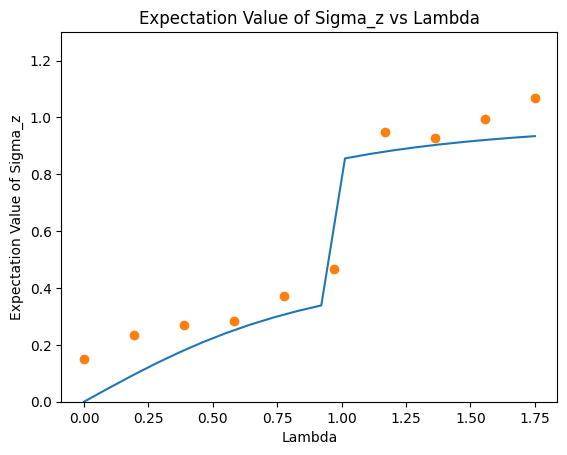

In [ ]:
# plot todo jutno

sig=np.array([-5.55111512e-17,0.04585852,0.09058121,0.13316769,0.17285268,0.20915007,0.24184306,0.27093748,0.29659952,0.31909473,0.33873788,0.8558566,0.87076789,0.88376474,0.8951099,0.90503424,0.91373789,0.92139275,0.92814565,0.93412157])
lambda_values2= np.linspace(0,1.75,20)
lambda_values= np.linspace(0,1.75,10)
plt.plot(lambda_values2, sig)
plt.plot(lambda_values, mean_sigz_med_qyoto_2048,'o')
plt.ylim([0,1.3])
plt.xlabel('Lambda')
plt.ylabel('Expectation Value of Sigma_z')
plt.title('Expectation Value of Sigma_z vs Lambda')
plt.show()

Figura 6

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from qiskit import QuantumCircuit, Aer, transpile, assemble, QuantumRegister, ClassicalRegister
from qiskit.visualization import plot_histogram
from numpy import pi

# Function to create the quantum circuit
def create_circuit_6(lamb,t):
    qreg_q = QuantumRegister(4, 'q')
    circuit = QuantumCircuit(qreg_q)
    initial_state = [1, 0, 0, 0,0,0,0,0,0,0,0,0,0,0,0,0]
    # Amplitude for |0000⟩ is 1, all others are 0
    # Initialize the quantum circuit to the desired state
    circuit.initialize(initial_state, circuit.qubits)

    #variables
    k=1
    n=4
    theta0 =np.arccos((lamb-np.cos(2*pi*0/n))/(np.sqrt((lamb-np.cos(2*pi*0/n))**2+np.sin(2*pi*0/n)**2)))
    theta1 =np.arccos((lamb-np.cos(2*pi*1/n))/(np.sqrt((lamb-np.cos(2*pi*k/n))**2+np.sin(2*pi*k/n)**2)))
    phi    =np.arccos(lamb/(np.sqrt(lamb**2+1)))/2
    phase  =4*t*np.sqrt(1+lamb**2)+np.pi/2
    circuit.ry(phi, qreg_q[0])
    #circuit.ry(phi, qreg_q[1])
    circuit.u(0, 0, phase, qreg_q[0])
    #circuit.u(0, 0, phase, qreg_q[1])
    circuit.cx(qreg_q[0], qreg_q[1])
#    circuit.ry(phi, qreg_q[2])
#    circuit.u(0, 0, phase, qreg_q[2])
#    circuit.cx(qreg_q[2], qreg_q[3])
    circuit.x(qreg_q[1])
    circuit.x(qreg_q[3])
    circuit.cx(qreg_q[1], qreg_q[0])
    circuit.cx(qreg_q[3], qreg_q[2])
    circuit.rz(pi / 2, qreg_q[1])
    circuit.rz(pi / 2, qreg_q[3])
    circuit.cx(qreg_q[0], qreg_q[1])
    circuit.cx(qreg_q[2], qreg_q[3])
    circuit.ry(-theta1 / 2, qreg_q[1])
# here we have +pi/2 as it is the transpose conjugate
    circuit.ry(-theta0 / 2, qreg_q[3])
    circuit.cx(qreg_q[0], qreg_q[1])
    circuit.cx(qreg_q[2], qreg_q[3])
    circuit.ry(theta1 / 2, qreg_q[1])
    circuit.ry(theta0 / 2, qreg_q[3])
    circuit.rz(-pi / 2, qreg_q[1])
    circuit.rz(-pi / 2, qreg_q[3])
    circuit.cx(qreg_q[1], qreg_q[0])
    circuit.cx(qreg_q[3], qreg_q[2])
    circuit.x(qreg_q[1])
    circuit.x(qreg_q[3])
    circuit.cz(qreg_q[0], qreg_q[1])
    circuit.cz(qreg_q[2], qreg_q[3])
    circuit.cx(qreg_q[0], qreg_q[1])
    circuit.cx(qreg_q[2], qreg_q[3])
    #ch's to be changed
    circuit.h(qreg_q[0])
    circuit.cx(qreg_q[1], qreg_q[0])
    circuit.h(qreg_q[0])

    circuit.h(qreg_q[2])
    circuit.cx(qreg_q[3], qreg_q[2])
    circuit.h(qreg_q[2])

    circuit.cx(qreg_q[0], qreg_q[1])
    circuit.cx(qreg_q[2], qreg_q[3])
    circuit.u(0, 0, -2 * pi / 4, qreg_q[0])
    circuit.u(0, 0, 0, qreg_q[2])
    circuit.cx(qreg_q[1], qreg_q[2])
    circuit.cx(qreg_q[2], qreg_q[1])
    circuit.cx(qreg_q[1], qreg_q[2])
    circuit.h(qreg_q[2])
    circuit.cx(qreg_q[1], qreg_q[2])
    circuit.h(qreg_q[2])
    circuit.cz(qreg_q[0], qreg_q[1])
    circuit.cx(qreg_q[0], qreg_q[1])
    circuit.cz(qreg_q[2], qreg_q[3])

    circuit.h(qreg_q[0])
    circuit.cx(qreg_q[1], qreg_q[0])
    circuit.h(qreg_q[0])
    circuit.cx(qreg_q[2], qreg_q[3])
    circuit.cx(qreg_q[0], qreg_q[1])
    circuit.h(qreg_q[2])
    circuit.cx(qreg_q[3], qreg_q[2])
    circuit.h(qreg_q[2])

    circuit.u(0, 0, 0, qreg_q[0])
    circuit.cx(qreg_q[2], qreg_q[3])
    circuit.u(0, 0, 0, qreg_q[2])
    circuit.cx(qreg_q[1], qreg_q[2])
    circuit.cx(qreg_q[2], qreg_q[1])
    circuit.cx(qreg_q[1], qreg_q[2])
    circuit.h(qreg_q[2])
    circuit.cx(qreg_q[1], qreg_q[2])
    circuit.h(qreg_q[2])

    # Apply gates based on the lambda parameter
    # Modify this part based on your specific circuit

    # Measure all qubits
    #circuit.measure_all()

    return circuit

<ipython-input-23-f22dc07acd5d>:29: DeprecationWarning: Using a qobj for run() is deprecated as of qiskit-aer 0.9.0 and will be removed no sooner than 3 months from that release date. Transpiled circuits should now be passed directly using `backend.run(circuits, **run_options).
  result = simulator.run(assemble(transpiled_circuit)).result()


-0.07467459582397995
-0.10024846213748273
-0.17140661221915976
-0.27266899608300443
-0.38200655926209715
-0.47563353805378805
-0.533181916846786
-0.5421323738303554
-0.5005377881006444
-0.4174468247157562
-0.3109354491850115
-0.20417460419595493
-0.12038950309494123
-0.0778071170952126
-0.0856910015736668
-0.1423260623960374
-0.23539166487066132
-0.34464191760447516
-0.4463100507845751
-0.5182787414928488
-0.04324996830563185
-0.06686723982755893
-0.13034108942359324
-0.21384247636903686
-0.29128581718584967
-0.3384780438832543
-0.3406764460217937
-0.29719424935015293
-0.22161516202671006
-0.13754986482803555
-0.07126010510827877
-0.04345460549067873
-0.06281972087251919
-0.12330584714141676
-0.20601729940196323
-0.2851152674085028
-0.3358897825861892
-0.3424790382911408
-0.30282457075362446
-0.229314317001596
0.9840141108637128
0.9625200866859174
0.9132077957620726
0.8708802455603465
0.8654108412335244
0.9006597100656293
0.9517493494660223
0.982622357349209
0.9714895711394183
0.926208

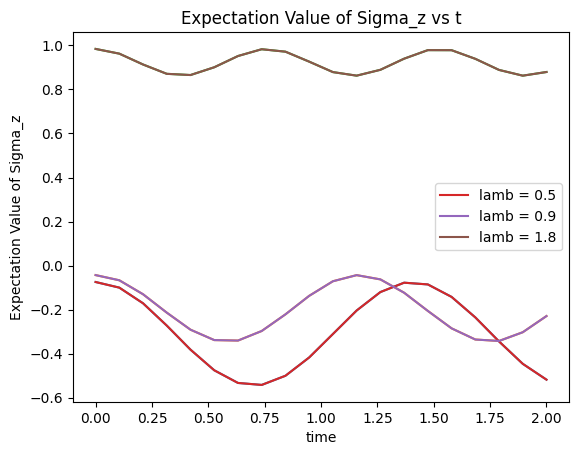

In [ ]:
from qiskit import QuantumCircuit, Aer, transpile, assemble
import numpy as np

from qiskit.primitives import Estimator

estimator = Estimator()

from qiskit.quantum_info import SparsePauliOp

observable=SparsePauliOp(['IZII', 'ZIII', 'IIIZ','IIZI'], coeffs=[0.25 +0.j,  0.25+0.j,  0.25 +0.j,  0.25 +0.j])

# Define a range of lambda values
#lambda_values = np.array([0.5,0.9,1.8])
lambda_values = np.array([0.5,0.9,1.8])
t_values = np.linspace(0, 2, 20)

# Simulate the circuit for each lambda value
expectation_values = []

expVals=np.zeros((len(t_values),len(lambda_values)))

for idx_lam,lambda_val in enumerate(lambda_values):
  for idx_t,t_val in enumerate(t_values):
    qc = create_circuit_6(lambda_val,t_val)

    # Use Aer simulator
    simulator = Aer.get_backend('qasm_simulator')
    transpiled_circuit = transpile(qc, simulator)
    result = simulator.run(assemble(transpiled_circuit)).result()

    # Calculate and store the expectation value
    job =estimator.run(qc, observable)
    #expectation_value=float(job.result())
    #print(job.result())
    print(job.result().values[0])
    expectation_value=job.result().values[0]
    expectation_values.append(expectation_values)
    expVals[idx_t,idx_lam] = job.result().values[0]




# Plot the results
print(expVals)
exparray=np.array([-5.55111512e-17,0.04585852,0.09058121,0.13316769,])
plt.figure(1)
plt.plot(t_values, expVals)
I0 = plt.plot(t_values, expVals[:,0])
I1 = plt.plot(t_values, expVals[:,1])
I2 = plt.plot(t_values, expVals[:,2])
plt.legend( (I0[0], I1[0], I2[0]), ("lamb = 0.5", "lamb = 0.9","lamb = 1.8"))
#plt.ylim([0,1])
plt.plot()
plt.xlabel('time')
plt.ylabel('Expectation Value of Sigma_z')
plt.title('Expectation Value of Sigma_z vs t')
plt.show()

Thermal simulation

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from qiskit import QuantumCircuit, Aer, transpile, assemble, QuantumRegister, ClassicalRegister
from qiskit.visualization import plot_histogram
from numpy import pi

# Function to create the quantum circuit
def create_circuit_fig_2(lamb,inpt):
    qreg_q = QuantumRegister(4, 'q')
    circuit = QuantumCircuit(qreg_q)
    #initial_state = [1, 0, 0, 0,0,0,0,0,0,0,0,0,0,0,0,0]
    # Amplitude for |0000⟩ is 1, all others are 0
    # Initialize the quantum circuit to the desired state
    #circuit.initialize(initial_state, circuit.qubits)

    #variables
    k=1
    n=4
    theta0 =np.arccos((lamb-np.cos(2*pi*0/n))/(np.sqrt((lamb-np.cos(2*pi*0/n))**2+np.sin(2*pi*0/n)**2)))
    theta1 =np.arccos((lamb-np.cos(2*pi*1/n))/(np.sqrt((lamb-np.cos(2*pi*k/n))**2+np.sin(2*pi*k/n)**2)))
#   phi    =np.arccos(lamb/(np.sqrt(lamb**2+1)))/2
#   phase  =4*t*np.sqrt(1+lamb**2)
    for i,c in enumerate(inpt):
      if c== -1:
        circuit.x(qreg_q[i])

    # circuit.ry(theta1 , qreg_q[0])
    # circuit.u(0, 0, + pi/2, qreg_q[0])
    # circuit.cx(qreg_q[0], qreg_q[1])
    # circuit.ry(theta0 , qreg_q[2])
    # circuit.u(0, 0, + pi/2, qreg_q[2])
    # circuit.cx(qreg_q[2], qreg_q[3])
    circuit.x(qreg_q[1])
    circuit.x(qreg_q[3])
    circuit.cx(qreg_q[1], qreg_q[0])
    circuit.cx(qreg_q[3], qreg_q[2])
    circuit.rz(pi / 2, qreg_q[1])
    circuit.rz(pi / 2, qreg_q[3])
    circuit.cx(qreg_q[0], qreg_q[1])
    circuit.cx(qreg_q[2], qreg_q[3])
    circuit.ry(-theta1 / 2, qreg_q[1])
# here we have +pi/2 as it is the transpose conjugate
    circuit.ry(-theta0 / 2, qreg_q[3])
    circuit.cx(qreg_q[0], qreg_q[1])
    circuit.cx(qreg_q[2], qreg_q[3])
    circuit.ry(theta1 / 2, qreg_q[1])
    circuit.ry(theta0 / 2, qreg_q[3])
    circuit.rz(-pi / 2, qreg_q[1])
    circuit.rz(-pi / 2, qreg_q[3])
    circuit.cx(qreg_q[1], qreg_q[0])
    circuit.cx(qreg_q[3], qreg_q[2])
    circuit.x(qreg_q[1])
    circuit.x(qreg_q[3])
    circuit.cz(qreg_q[0], qreg_q[1])
    circuit.cz(qreg_q[2], qreg_q[3])
    circuit.cx(qreg_q[0], qreg_q[1])
    circuit.cx(qreg_q[2], qreg_q[3])
    #ch's to be changed
    circuit.h(qreg_q[0])
    circuit.cx(qreg_q[1], qreg_q[0])
    circuit.h(qreg_q[0])

    circuit.h(qreg_q[2])
    circuit.cx(qreg_q[3], qreg_q[2])
    circuit.h(qreg_q[2])

    circuit.cx(qreg_q[0], qreg_q[1])
    circuit.cx(qreg_q[2], qreg_q[3])
    circuit.u(0, 0, -2 * pi / 4, qreg_q[0])
    circuit.u(0, 0, 0, qreg_q[2])
    circuit.cx(qreg_q[1], qreg_q[2])
    circuit.cx(qreg_q[2], qreg_q[1])
    circuit.cx(qreg_q[1], qreg_q[2])
    circuit.h(qreg_q[2])
    circuit.cx(qreg_q[1], qreg_q[2])
    circuit.h(qreg_q[2])
    circuit.cz(qreg_q[0], qreg_q[1])
    circuit.cx(qreg_q[0], qreg_q[1])
    circuit.cz(qreg_q[2], qreg_q[3])

    circuit.h(qreg_q[0])
    circuit.cx(qreg_q[1], qreg_q[0])
    circuit.h(qreg_q[0])
    circuit.cx(qreg_q[2], qreg_q[3])
    circuit.cx(qreg_q[0], qreg_q[1])
    circuit.h(qreg_q[2])
    circuit.cx(qreg_q[3], qreg_q[2])
    circuit.h(qreg_q[2])

    circuit.u(0, 0, 0, qreg_q[0])
    circuit.cx(qreg_q[2], qreg_q[3])
    circuit.u(0, 0, 0, qreg_q[2])
    circuit.cx(qreg_q[1], qreg_q[2])
    circuit.cx(qreg_q[2], qreg_q[1])
    circuit.cx(qreg_q[1], qreg_q[2])
    circuit.h(qreg_q[2])
    circuit.cx(qreg_q[1], qreg_q[2])
    circuit.h(qreg_q[2])

    # Apply gates based on the lambda parameter
    # Modify this part based on your specific circuit

    # Measure all qubits
    #circuit.measure_all()

    return circuit

Gráfica

In [ ]:
from qiskit import QuantumCircuit, Aer, transpile, assemble
import numpy as np
from itertools import permutations, product
from qiskit.primitives import Estimator

estimator = Estimator()

from qiskit.quantum_info import SparsePauliOp

observable=SparsePauliOp(['IZII', 'ZIII', 'IIIZ','IIZI'], coeffs=[0.25 +0.j,  0.25+0.j,  0.25 +0.j,  0.25 +0.j])

def particion(B,N,lamb):
  observable=SparsePauliOp(['IZII', 'ZIII', 'IIIZ','IIZI'], coeffs=[0.25 +0.j,  0.25+0.j,  0.25 +0.j,  0.25 +0.j])
  w = np.sqrt(lamb**2+1)
  observable_H=SparsePauliOp(['XXII', 'IXXI', 'IIXX','XIIX','YZZY','ZIII','IZII','IIZI','IIIZ'], coeffs=[1 +0.j,  1+0.j,  1 +0.j,1 +0.j,  1 +0.j,-lamb+0.j,-lamb+0.j,-lamb+0.j,-lamb+0.j])
  #observable_H=SparsePauliOp(['XXII', 'IXXI', 'IIXX','XIIX','ZIII','IZII','IIZI','IIIZ'], coeffs=[1 +0.j,  1+0.j,  1 +0.j,1 +0.j,-lamb+0.j,-lamb+0.j,-lamb+0.j,-lamb+0.j])
  cases = list(product("01", repeat=N))
  #cases = list(map(list, cases))
  cases = 1-2*np.array(cases,dtype=int)

  #cases[cases == 1] = -1
  #cases[cases == 0] = 1

  # SUM nos dará la suma de los estados de cada partícula mientras que PRD nos da la suma de
  # los productos de los sigmas vecinos

  #SUM = cases.sum(axis=1)
#  PRD = cases*roll(cases,1,axis=1)
  # if N <= 3: PRD[:,0] = 0
#  PRD = PRD.sum(axis=1)

  #Z  = np.exp(-B*w*SUM)         # Numerador de la probabilidad que llamaremos función de partición parcial
  #ZT = (np.exp(-B*w*SUM)).sum() # Función de partición total
  #p  = Z/ZT                         # Probabilidad de un estado

  sigma_z = 0.0
  ZT = 0.0
  for j in range(cases.shape[0]):
      caseo = cases[j, :]
      qc = create_circuit_fig_2(lamb, caseo)
      simulator = Aer.get_backend('qasm_simulator')
      transpiled_circuit = transpile(qc, simulator)

        # Ejecuta el circuito transpilado
      #qobj = assemble(transpiled_circuit, shots=1024)
      #result = simulator.run(qobj).result()

        # Calcula y almacena el valor esperado
      job = estimator.run(qc, observable)
      job2 = estimator.run(qc, observable_H)
      sigma_z += np.exp(-B * (job2.result().values[0]))*(job.result().values[0])
      #sigma_z += np.exp(-B * (w*caseo.sum()))*(job.result().values[0])
      #print('sigma_z',job.result().values[0], 'y su energía',job2.result().values[0])
      #print('H',job2.result().values[0])
      ZT += np.exp(-B * (job2.result().values[0]))

  sigma_z =sigma_z/ ZT
  return sigma_z


N = 4





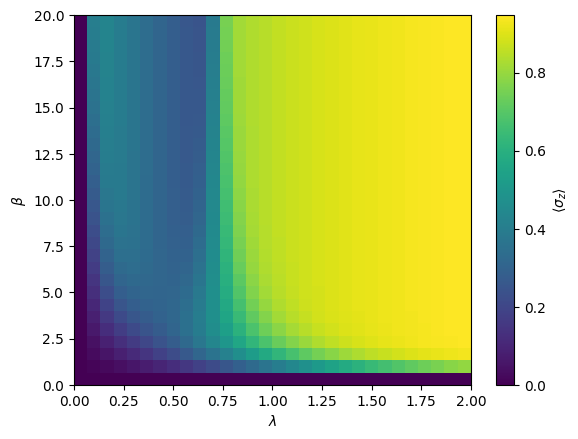

In [ ]:
# Define a range of lambda values
#lambda_values = np.array([0.5,0.9,1.8])
lambda_values = np.linspace(0,2,30)
B_values = np.linspace(0, 20, 30)

# Simulate the circuit for each lambda value
expVals=np.zeros((len(B_values),len(lambda_values)))

for idx_lam,lambda_val in enumerate(lambda_values):
  for idx_B,B_val in enumerate(B_values):
    #print('lambda_val at','',lambda_val)
    #print('B_val',B_val)

    expVals[idx_B,idx_lam] = particion(B_val,N,lambda_val)



# Plot the results
plt.imshow(expVals, extent=[min(lambda_values), max(lambda_values), min(B_values), max(B_values)], origin='lower', aspect='auto', cmap='viridis')

# Agregar barra de color
plt.colorbar(label=r'$\langle \sigma_z \rangle$')
plt.xlabel(r'$\lambda$')
plt.ylabel(r'$\beta$')
# Etiquetas de los ejes


# Título
#plt.title('Valor esperado de sigma_z(Beta)')

# Mostrar la gráfica
plt.show()

MonteCarlo

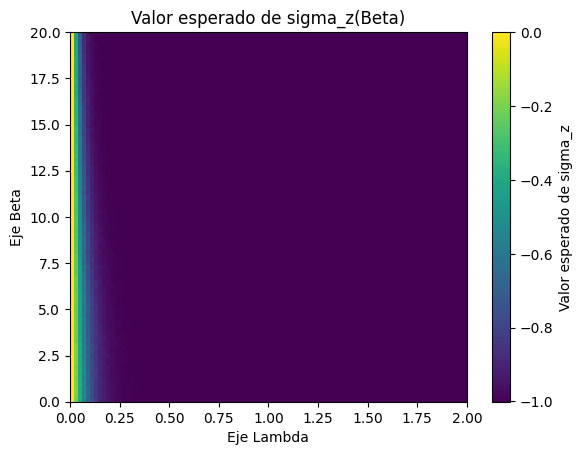

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from random import *



#Se definen los vectores y parámetros necesarios:

m = np.zeros(N)        # Se genera la matriz que contendrá los espines de cada partícula

N = 4
lambda_values = np.linspace(0,2,100)
B_values = np.linspace(0, 20, 100)

# Veces que se realiza el experimento de montecarlo para ser más fiable

t0 = 0
tmax = 1000
t_val = np.arange(t0, tmax+1, 1)

# Matriz de spines

def create(N):
    for i in range(N):
          r = uniform(0,1)
          if r < 0.5:
              m[i] = -1
          else:
              m[i] = 1

    return m

#Ahora se define la función que crea la combinación de términos de m
#requerida por el modelo

def energia_sist(N , m, i):

    E = 0
    for i,c in enumerate(m):
      E += c
    return E

# Se define el algortimo que impone las condiciones físicas por el método de
# montecarlo y se aplica a cada temperatura

sig=np.zeros((len(lambda_values),len(B_values)))

for idx_lam,lambda_val in enumerate(lambda_values):
  for idx_B,B_val in enumerate(B_values):
    w = np.sqrt(lambda_val**2+1)

    espin = create(N)
    for t in t_val:
      for i in range(N):
        E1 = w*energia_sist(N , m, i)
        espin[i] = -espin[i]
        E2 = w*energia_sist(N , m, i)

        Ev = E2-E1        #Se define la energía de volteo


    #Se imponen las condiciones del algoritmo estudiado
        if Ev <= 0:
          espin[i] = espin[i]
        else:
          r = uniform(0, 1)
          if r <= np.exp(-Ev*B_val):
            espin[i] = espin[i]
          else:
            espin[i] = -espin[i]

#Se obtiene la magnetización media (M) y la magnetización (mag)
        sig[idx_lam,idx_B] += espin[i]/(tmax*N)



# Plot the results
plt.imshow(sig, extent=[min(lambda_values), max(lambda_values), min(B_values), max(B_values)], origin='lower', aspect='auto', cmap='viridis')

# Agregar barra de color
plt.colorbar(label='Valor esperado de sigma_z')

# Etiquetas de los ejes
plt.xlabel('Eje Lambda')
plt.ylabel('Eje Beta')

# Título
plt.title('Valor esperado de sigma_z(Beta)')

# Mostrar la gráfica
plt.show()

Esto en teoría tendría que estar bien pero a estas alturas a saber

Asunto sigmax

Circuito

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from qiskit import QuantumCircuit, Aer, transpile, assemble, QuantumRegister, ClassicalRegister
from qiskit.visualization import plot_histogram
from numpy import pi

# Function to create the quantum circuit
def create_circuit_x(lamb,t):
    qreg_q = QuantumRegister(4, 'q')
    circuit = QuantumCircuit(qreg_q)
    initial_state = [1, 0, 0, 0,0,0,0,0,0,0,0,0,0,0,0,0]
    # Amplitude for |0000⟩ is 1, all others are 0
    # Initialize the quantum circuit to the desired state
    circuit.initialize(initial_state, circuit.qubits)

    #variables
    k=1
    n=4
    theta0 =np.arccos((lamb-np.cos(2*pi*0/n))/(np.sqrt((lamb-np.cos(2*pi*0/n))**2+np.sin(2*pi*0/n)**2)))
    theta1 =np.arccos((lamb-np.cos(2*pi*1/n))/(np.sqrt((lamb-np.cos(2*pi*k/n))**2+np.sin(2*pi*k/n)**2)))
#    phi    =np.arccos(lamb/(np.sqrt(lamb**2+1)))/2
    phase  =4*t*np.sqrt(1+lamb**2)


    circuit.ry(theta1 , qreg_q[0])
    circuit.u(0, 0, phase + pi/2, qreg_q[0])
    circuit.cx(qreg_q[0], qreg_q[1])
    circuit.ry(theta0 , qreg_q[2])
    circuit.u(0, 0, phase+ pi/2, qreg_q[2])
    circuit.cx(qreg_q[2], qreg_q[3])
#    circuit.ry(phi, qreg_q[2])
#    circuit.u(0, 0, phase, qreg_q[2])
#    circuit.cx(qreg_q[2], qreg_q[3])
    circuit.x(qreg_q[1])
    circuit.x(qreg_q[3])
    circuit.cx(qreg_q[1], qreg_q[0])
    circuit.cx(qreg_q[3], qreg_q[2])
    circuit.rz(pi / 2, qreg_q[1])
    circuit.rz(pi / 2, qreg_q[3])
    circuit.cx(qreg_q[0], qreg_q[1])
    circuit.cx(qreg_q[2], qreg_q[3])
    circuit.ry(-theta1 / 2, qreg_q[1])
# here we have +pi/2 as it is the transpose conjugate
    circuit.ry(-theta0 / 2, qreg_q[3])
    circuit.cx(qreg_q[0], qreg_q[1])
    circuit.cx(qreg_q[2], qreg_q[3])
    circuit.ry(theta1 / 2, qreg_q[1])
    circuit.ry(theta0 / 2, qreg_q[3])
    circuit.rz(-pi / 2, qreg_q[1])
    circuit.rz(-pi / 2, qreg_q[3])
    circuit.cx(qreg_q[1], qreg_q[0])
    circuit.cx(qreg_q[3], qreg_q[2])
    circuit.x(qreg_q[1])
    circuit.x(qreg_q[3])
    circuit.cz(qreg_q[0], qreg_q[1])
    circuit.cz(qreg_q[2], qreg_q[3])
    circuit.cx(qreg_q[0], qreg_q[1])
    circuit.cx(qreg_q[2], qreg_q[3])
    #ch's to be changed
    circuit.h(qreg_q[0])
    circuit.cx(qreg_q[1], qreg_q[0])
    circuit.h(qreg_q[0])

    circuit.h(qreg_q[2])
    circuit.cx(qreg_q[3], qreg_q[2])
    circuit.h(qreg_q[2])

    circuit.cx(qreg_q[0], qreg_q[1])
    circuit.cx(qreg_q[2], qreg_q[3])
    circuit.u(0, 0, -2 * pi / 4, qreg_q[0])
    circuit.u(0, 0, 0, qreg_q[2])
    circuit.cx(qreg_q[1], qreg_q[2])
    circuit.cx(qreg_q[2], qreg_q[1])
    circuit.cx(qreg_q[1], qreg_q[2])
    circuit.h(qreg_q[2])
    circuit.cx(qreg_q[1], qreg_q[2])
    circuit.h(qreg_q[2])
    circuit.cz(qreg_q[0], qreg_q[1])
    circuit.cx(qreg_q[0], qreg_q[1])
    circuit.cz(qreg_q[2], qreg_q[3])

    circuit.h(qreg_q[0])
    circuit.cx(qreg_q[1], qreg_q[0])
    circuit.h(qreg_q[0])
    circuit.cx(qreg_q[2], qreg_q[3])
    circuit.cx(qreg_q[0], qreg_q[1])
    circuit.h(qreg_q[2])
    circuit.cx(qreg_q[3], qreg_q[2])
    circuit.h(qreg_q[2])

    circuit.u(0, 0, 0, qreg_q[0])
    circuit.cx(qreg_q[2], qreg_q[3])
    circuit.u(0, 0, 0, qreg_q[2])
    circuit.cx(qreg_q[1], qreg_q[2])
    circuit.cx(qreg_q[2], qreg_q[1])
    circuit.cx(qreg_q[1], qreg_q[2])
    circuit.h(qreg_q[2])
    circuit.cx(qreg_q[1], qreg_q[2])
    circuit.h(qreg_q[2])
    circuit.h(qreg_q[2])
    circuit.h(qreg_q[1])
    circuit.h(qreg_q[0])
    circuit.h(qreg_q[3])

    # Apply gates based on the lambda parameter
    # Modify this part based on your specific circuit

    # Measure all qubits
    #circuit.measure_all()

    return circuit

Gráfica

<ipython-input-4-d4a9e0895678>:30: DeprecationWarning: Using a qobj for run() is deprecated as of qiskit-aer 0.9.0 and will be removed no sooner than 3 months from that release date. Transpiled circuits should now be passed directly using `backend.run(circuits, **run_options).
  result = simulator.run(assemble(transpiled_circuit)).result()


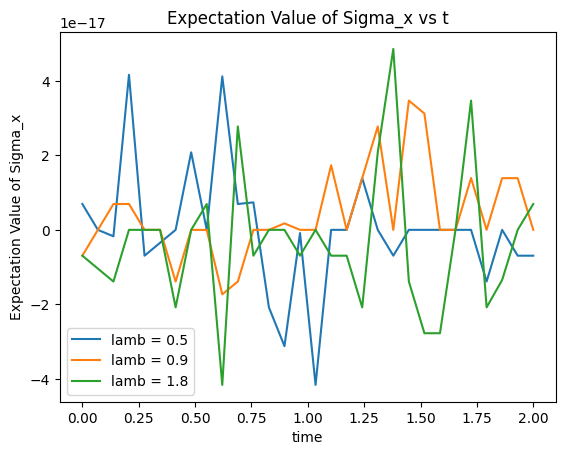

In [ ]:
from qiskit import QuantumCircuit, Aer, transpile, assemble
import numpy as np

from qiskit.primitives import Estimator

estimator = Estimator()

from qiskit.quantum_info import SparsePauliOp

observable=SparsePauliOp(['IZII', 'ZIII', 'IIIZ','IIZI'], coeffs=[0.25 +0.j,  0.25+0.j,  0.25 +0.j,  0.25 +0.j])

# Define a range of lambda values
#lambda_values = np.array([0.5,0.9,1.8])
lambda_values = np.array([0.5,0.9,1.8])
t_values = np.linspace(0, 2, 30)

# Simulate the circuit for each lambda value


expValsx=np.zeros((len(t_values),len(lambda_values)))

for idx_lam,lambda_val in enumerate(lambda_values):

  for idx_t,t_val in enumerate(t_values):
    qc = create_circuit_x(lambda_val,t_val)

    # Use Aer simulator
    simulator = Aer.get_backend('qasm_simulator')
    transpiled_circuit = transpile(qc, simulator)
    result = simulator.run(assemble(transpiled_circuit)).result()

    # Calculate and store the expectation value
    job =estimator.run(qc, observable)


    expectation_value=job.result().values[0]
    expValsx[idx_t,idx_lam] = job.result().values[0]




# Plot the results
plt.figure(1)
#plt.plot(t_values, expVals)
I0 = plt.plot(t_values, expValsx[:,0])
I1 = plt.plot(t_values, expValsx[:,1])
I2 = plt.plot(t_values, expValsx[:,2])
plt.legend( (I0[0], I1[0], I2[0]), ("lamb = 0.5", "lamb = 0.9","lamb = 1.8"))

#plt.ylim([0,1])
plt.plot()
plt.xlabel('time')
plt.ylabel('Expectation Value of Sigma_x')
plt.title('Expectation Value of Sigma_x vs t')
plt.show()

In [ ]:
Medidas

In [ ]:
def sigz(vec):
  mean_sigz= vec[0]*-1+vec[1]*-1+vec[2]*1+vec[3]*1
  mean_sigz_med= 0.25*mean_sigz
  return mean_sigz_med

first = np.array([0.188851521456792,0.31682188135063755,0.19602015350207336,0.2983064436904971])
sec = np.array([0.18110648464703843,0.31935781769400967,0.22496687535139676,0.2745688223075552])
thrd = np.array([0.192331732849263,0.3341765211780643,0.21289030662442124,0.2606014393482515])
forth = np.array([0.20329356635842102,0.2964680477035745,0.1680078152302672,0.3322305707077373])
fifth = np.array([0.21899311575493513,0.29064058891583155,0.1877995877183672,0.3025667076108661])
sixth = np.array([0.20960484454015785,0.29186858222710904,0.22468237586557896,0.27384419736715415])
seventh = np.array([0.17920412357342896,0.37896489240548104,0.18367375730056087,0.2581572267205291])
eighth = np.array([0.24092247022411203,0.27752631477967216,0.18402809171021356, 0.2975231232860022])
nineth = np.array([0.21467818796598723,0.31812057135086613,0.22094653109304774,0.24625470959009893])


final = np.zeros(9)
t_values2= np.linspace(0,2,9)
final[0] = sigz(first)
final[1] = sigz(sec)
final[2] = sigz(thrd)
final[3] = sigz(forth)
final[4] = sigz(fifth)
final[5] = sigz(sixth)
final[6] = sigz(seventh)
final[7] = sigz(eighth)
final[8] = sigz(nineth)
print(final)
plt.figure(1)

#I0 = plt.plot(t_values, expVals[:,0])
I1 = plt.plot(t_values, expValsx[:,1])
#I2 = plt.plot(t_values, expVals[:,2])
#plt.legend( (I0[0], I1[0], I2[0]), ("lamb = 0.5", "lamb = 0.9","lamb = 1.8"))

#plt.ylim([0,1])
plt.title('Expectation Value of Sigma_z vs t')
I2 = plt.plot(t_values2, final,'o')
#plt.ylim([0,1.3])
plt.xlabel('time')
plt.ylabel('Expectation Value of Sigma_z')
plt.title('Expectation Value of Sigma_z vs time')
plt.legend( (I1[0],I2[0]), ("teórico","ordenador cuántico"))
plt.show()